# 3. Revisión del estado del arte y selección de los modelos base

En este capítulo revisamos de forma sistemática los estudios que clasifican imágenes de residuos con Deep Learning sobre TrashNet. A partir de la revisión seleccionamos tres modelos base, los analizamos en detalle y comparamos críticamente la evidencia publicada. Los datos de la revisión (registros, decisiones, tabla de síntesis, calidad y frecuencia de modelos) están incrustados en el cuaderno.

> **Resumen.** De 301 registros (Scopus, IEEE Xplore, Web of Science y arXiv) quedaron 168 únicos y 59 estudios incluidos tras la lectura del texto completo. ResNet (39 estudios), MobileNet (24) y VGG (22) son las familias de Deep Learning más frecuentes. La mediana de accuracy reportada en TrashNet es cercana a 96 %, pero solo 13 de los 59 estudios aplican pruebas estadísticas.

## 1. Configuración y datos

In [1]:
import gzip, base64, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 80)

# Paleta del proyecto (fondo blanco)
C0, C1, C2, C3, C4 = "#0B132B", "#1C2541", "#3A506B", "#5BC0BE", "#6FFFE9"
GRIS = "#B8C4D0"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 12, "axes.edgecolor": C2, "axes.labelcolor": C0,
    "xtick.color": C0, "ytick.color": C0, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})
GUARDAR = True     # True: guarda figuras (PNG, 200 dpi) y tablas en results/estado_arte/

from pathlib import Path
def find_repo_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").is_dir():
            return p
    return start                      # fuera del repo: guarda junto al cuaderno
OUT = find_repo_root() / "results" / "estado_arte"
OUT.mkdir(parents=True, exist_ok=True)

Datos de la revisión, generados desde `seleccion_PRISMA_TrashNet.xlsx` (JSON comprimido y codificado en base64). Contienen cuatro tablas: `registros` (168 registros únicos con su decisión), `estudios` (59 incluidos, con síntesis y calidad), `frecuencia` (familias de modelos) y `bitacora` (cadenas de búsqueda).

In [2]:
DATOS_B64 = """
H4sIAF7l72oC/+19W2/bSrbmXyECBEgwliySIiVlTw/gWxJn247b8s5ldzc2aIm2mEiimpSSeDcO0PM2zzPAAOexnwb90MBpHGAe
DuZp0r+kf8l8a1WRLF50oSzGijFA4EgUL8WqWve1vvWnR4F744XTwA8fPdN+96dHXh//P7poNPRHO9ojZ+z5+G40DB3fpt6Evj3a
C6Zeb+jSCT1v6tCVRrtdb+B73+39Mg3opONxbzjzgkfRwV7m4Mifep98eVw9wFc/+pcdTRmMkRqM3lYGc+CPr93AHfdcbeJM3CA1
qmanylGZ6VF1lkyR3qpyMM31pkhvNasclTV/ihaOyqx0VHapva3rle7tVnowxrLBZGfmcNb3Qz89lqMvxWPpemMtcIdOz/v672Ot
7wVub+poPX+s9YZO6F17vegnV/NGX/9y447dkL4Ebuj1Z2ASS16mnX6Z5pKXaVRKEp30YBrLBqNnBqPMYjKY5aO4+ySnXkNvlJrT
TqPCKdX1UlPasqoci1FuLEaVYzHnj2URn7Pb27nlmqUYpG1WObVpEWKYS8ZS6fYvJzisKrUPvVWKLVhbutPapaSfZVc5o531iNiq
krMY5bi/pVc5Fr3UYjVX0uFKD8IoNwhzBXVp3fkwyw2l0n2SYdnW4rGYVaq0hrUeIZnWZnjUma/NQgdMx51oQ9cJxt74JjNCuxRV
mZVSVauUUKl2LO35Y1m4cvoKVFZ6MGvyY7NxRwtp5PfdoS+ElniK52i+Nvz6t7HraFdO6C4ZudkopbMYra2UzaZeikiMKpV901hv
LxgrqabVboZyUsKoUkqYzfljWTiNVWrV5priotpB2aVIWK9S1TdbpWR7pe4qs11uLFU6eMxOOddZlWNpNsrNS5WGTLMc417Jo7ju
UIxy01KlJ6FplpuWKhlxc01GrFep/TWtcotVJf9tluO/VbLf5gJPy6K12k6PS7O93s5rV6DhNzvrzWyrCseCtUBpLzOY7Vhmq5yv
pkrRaK2pu2/pxJaTIlXKeau53o61KyEfq9SGsytgJ5a9nveimvlobdNgMkzfXuJF3k7K65RST6p0R9iN7RmKvh4TsKrYZ7ZRap9V
meRhm6WWqNKhNLdnKFYp6VXpUOz1lL9Kokp2a5sG096mwXS2Zse0GuspkpXMS0svxeqqdGy0FjhZFgZKKpmXcnzXrEAPbDXvfwjl
+GwlQ1iTv1azK1rreR2qGUy7XMR1K7XhVmfNUG0VM9pulGKGVXpW2/r2DGWBNrwwsFXJEpnbMy/N9eSVUQGXbFtbNJZyWSnVbJPW
euZkNYNZMx2lmsF0ShFQlYGaTslgY5VD0dejH72KJeoYm5+X0mMwNzMhm2AoneY2LY61TYMpx2orpaA1XQ/VzEt7mwbTWU8WVTEY
vdHYpsHo2zSYNdXcxjbaVXqjnJ68pS/R3MySbGZ/WHea0Q3yWj1b+XmfQ2k9KKppb9OG62zRYPTGQ1pnXd+mqd2Q4NmAqq3rdxMb
GxlC8/6HsD2sXt8eVq+3tolo2g+KH3W2hwUYD4rTG/qDepstEhXG/YsK4/5FhWFtEVM0tkdYGNskLIxtUuuNLeL1ZmOLxqJvzeY1
H5QryDS3aPeb98+yTesBuMZM+0Ft0dZ6QZUtfZv2Zt5mI5u9s5mxbIT4F1WXfvvB6A9pzzWN7dlzTfNBzWxzi2bW2iYCsrdpMK1t
GswWCYBm5yERo7VNEsTSt2kwxjYNxtweArCa2zQx5bAJqjRyrW1i39aa2UPVDKa9TYPpbNFg7MY2DUZfL622msGs6TJ69KiCsZhb
NJbmRsayCUFgWxsZynYoQrZ97340e4HKfR64k8AbTyvfXu35tZRVjuEPOOSG01nfK+44AZA9+nrq+Nrbeu2kvqMdDNwxfT7A57fO
+EY7qNcu65o71ZxhXXtC/OtpXbtwe7e9IYA+tc9OOHV5b4jNMfWwVWYh/eRPpt7I+9Xt0/b55A9n9Jsz1MbuLOD/pp/94CPdLPRn
Qc8N8XR/HLrBJ3EXZ9xPHlTnl/c9Gi6gkJCTae9+qGPT4d7Yo3WaVBy1ck7x5a008O165o6nLs/MKoPhsTi4gTvl1boMnHBw5k53
tMu9g9c72gsnuHJuXO0gPS1PfnRubobu0x1NXqxNAn/i+WLhCPiQ73bo4rl8t+6bU+2JAoTYG379S4i7PeUr3GmAz3zJ6de/ii/P
NPeL05t6WPIdbeTg4K9EnJikaywK6HZH2/vpYPfi9UFde+MM/QC/Dol2ZyN3zJ+d2dQPnmmXAybp2XAaauHA/6xNB84Uf1xlWaOB
InqtOb2B537CQTpl4N0MsO1wsIel7t1q/rXW6dTtxzvaZ9pfPX80cQKc/NmbDjQflwQa71I3/Oef/1U7ODsLeb1xPd5uPBsOxZdf
rgNCgJR7HZM39Xv+kBdabHSnj+4qmAccuXaGoUvr5IVglCHmXzkYuiNvOOS5iw59vPaHfeX7J2fo9cHrUtc5NE3T6Og0mNHBnt/3
bnzlrEng4iysmdP35WkFDVYk7e0RLVzU90BvP7rhR7Dfbv2Cvji3jnaqUp7eBuVlthQmNtp82qHcVPv429fw4yFB8p5ISF7tlHZY
WNfOA7/nun0cCrUaNy/Rjo+OjrRjUEAwdiSRKpIGd9r3bvj2O/EnvjBLlMgF3L3ybmh31/n3tm0Yhr5+P5kUaW5w4PMIOEOJ4Lvu
hOd5V4s/g0MwcSZkeupfeUP6qD15o+++MXbfmKBxcZ72pDdzhn+cedji2LDXs3Ef26qP39/J+61Gy6tR7V6oOZJsaWsQLYL0+7Pe
FDvC/YIJ9mgDg7nRT1dEoxGRf8akadc+xqdhD9LPKnkLjn7tjd3adMbbiUnX0aYpOg8cCAMiduvxgyZgUyHgN762V38Jin3pk7zs
YreQIMXh03pKcuod0O+eduZ/woI9D5yRS/IPcx4IGs7S9k8850zE+H0cYlvH1FwXW3+vB0kVFpGhI36hp9aNjtXJAuOu0D8pRXzK
4+ZLv4Vijenh3XQ5YSSEtYD+VqMaLGTPk3LvrtIwIR9nGFONh1H3aNOzeDw8O6tdHmi3njvsh1qn+ZjVhk77MZOUG4xCIo6YWuKV
H9MmwZlvzmpT3gnR9NJzJtDAPWyZWz5lOpjhqaDu2RTDwR1wTyJWkM7UrfnXNXypOcFUw+QMfIyCHiJumlHS8O8Kojf9XtGDt4t6
JZ2miTc6szz1NhXqvXCunLEPmcvKL75MZ84YlPsjvnZvr0BqPV87yothfzTCBN5IRa9Q/x2xWMDa1hVhpTcw5Ysk1svZCAPysHnP
8P/U7Q3GmOObW6IGWm7xhEvlOI0FPLmXKKq4I3rMYdWOxp+8wB/TtPEPp84Yw6WvYFdnxwdHp3Pl+AB3dEeRGLdtM1OSVabnWYqT
bPlczOduS7T6DLsrUgpWY1rgWQ6RnGRNkNWeO5owKLo3jmyBldV32omEmw67xRXw6juR7IY4x5RPs5p6u1U3HpNhp6j6NGF/BGVM
6VtJ5qBvA3OQZy3lDZbKG2aQF2+IEXz9y7g3cH/Vvv5Xkuxf/zrE51f153npjtmnXdnTjkfYKjWhir9lGzm9beoQ5b3pDDrXGTY2
CRLau5MZiEHr9jymgCce2f2k8Grh7Aq2KOyj/GUkvHFXD0tJtDQcejd8NS1Z7uR9z/ci0umFT3NWdaO122m1a2YNXRVqese29Jr9
SyYFoUxfwRTlb8MbLzPd3zoX50sUmblW+XLVZqFB8ebFCxD90P1Ct9jFm/CtYAxrE5BSdKdVjX9V9Yk4ynN9iRq0o310JhOHrvZH
MLV8nN4L/LVZEFsYGeGYMjj8q6kDxtSXIpM8jaMrPhBPT01OKq+A0LNiZwP6oNqPVZ3qznqL5BMpziSPKYxJHon4kvy6nC1lDY5V
uZKtcKXuwNPIO3cJPSX20uVddHvFrjmhFrJEYB+Bo41ISAydW2zWwe1V4KXcdTln3d5kMvRwqaTYUHvShTT51Q2GoL4sPzHNTmMX
GwqFbO221TLKNgJNcY/FT96U2GYiXEbGKxDpPK/AHV16a1J1mpyXORG0oRNgwsaz0RVeHdSleA6IpTqJzylilGkXIbFNnzaY3G2S
Xsk5kdmOqt4xm2hTX+sY0k/o9QaaFwJOUG8LO6pJtM6uxYAeNRbPw4UhXm6uAbTD12JE9HwanHt9LSwqBC7CyEuSGbHCRmg8WTby
UGZouaZWxA4364NZ34xrK0zxpR+GLtltp+CIp84HcLHT+hG7UcOBO4J9tw8Xq8ojm8wjL6AXO1dDoTtc+FczyKsCtylb0UfRxpGB
AL6uWLdb1TljNMEjrWYri6G4vJNveefMSqGJFYyYFR00y7jo9vC7YxBZv+/R0HfItYLnuB7RIlESnlZDjAmX8R5wQagRzwi9L5GM
BWHd+KSsgl/AeoLjh07uOUH/ysefHa1jM5HS0Rua+R32DtFXzIGDl+pY9ZYpjrAejSNm3W7JI7gEm0CwMug8liWOD70ptOdvpPNk
abxI6dmsm1UU80sKP/GGAyyD9pNwzXgjx0OApIvPh84QGkq3gLrDEbG5Yj2IyVponVLtgRCvnXQvT4V5PI1crlFPQ57xEAwCCiuT
vps4FOraKWlRtOfA+n1/GPJSscoiHhgWmVohuEHTqAFRpoZIeatV+7Vk8+kUF1g6hE3pSMvUo29jyKzuuU2ELS+69JtmYpXyMSKm
BmpsWpCx104AG4aILJKn5AcmwsF+SHW8zCsO2+o3XZsa1YyB92R0/AziO/G0Q0FyDZAcpCHWmlTIM2E3nAm7QTpC4m3mD4ckSjHZ
iRcO7lbQ6aiE8GwgstHp2K12yTbp5WXn0oD+y5nz2YVdNvRpyy50H6zvGFQp4a7OwUStFLua/VWRvqrR4KFZ2s06UYE8Zc4kRC/r
8SVtgy8h1iMvy2nC4kSSiI3H2+VK3LD4Mgqs9nfgzheR1X6SUE4UF2QmXtuH8IGicQCeM8bBoy8TCCOabElPLIui9eClW18FhZmO
ZJocgscyKjI2TkUZOoni4wts5js53Mo545cqnUto7jn52oe3IvB+WruKw/+RayWRUle30EsSi7ADGwG64lyzsIDKiH4FDQ7gxe+5
AeksUHI/wYGPBYDV+4kybhaZzXRf9gxNhm4U5fSDsnHBxmr0utTBdgdqXdHFpjdT+XAh606cD+fMSPKTovkKNMuGZdbX1u0FzkQI
vjGZiR65qKakewU+GQww2osi/CWIVK+bcKIZ2UL4JS4021zXTFwoweI3XMHMk7+/W2YsRjZlhWbhEgp96yZ+ZSftd6EI/hxpthNF
36HQBn1BfUlGR5popViMI/f0oOEwUShHIkNL8T2JNoApEtuqYa6hy65H65v0putqjG9vGMD1HWrP60The6EXeLEXCVNDX9KWpSnU
3HlJr5+EDSGsR5q8IPG1l/O0/wRhCQ//EJbu1C1Of50hG5VC9Oi7jSPNLOj8ki6edtp8TD3vDqrwQtaxgnt9exxDZzgQ+JDFFCIP
5+qzfRepIOE0EGlALjaCez0bqt5lDBB5Ce64Hzt8I/dtLOWXe32telv1+lp1Q/X63gSuo5ipUCTyop0TKLw/ztwUj8F9szzmobz4
VmYirGw+qEE/2JdgLuT5OoGZSdmGrzwk7f+8XmZ+AZPC14kPPZEcW333E3J/oNZEzi4Pjsbb5ZG+cIbse6gpZSN9VjrPd9FjN+ve
Xj0T8Y2YsUtlxp688S53Mbbx02oT9dcy8Y+KkhXFC5QJS/VYw2BKnZ/Yb9c7KQKd6zAjB6sQhvkoG90ky4a+n5e4Xz1o3WQnXY2g
PXelR49de6+iUqCTFIcxyFMxVrJupkIXqnXBOziBQy2TAf0QI0kKEo5HHIfta6oFUc+kAL5C/Q39j1VRUvaoSMIN4Wwl2YGHnM+u
4NfWXrrOcDooYkbeBzeYDPSOYaI2td0q1S7XstN2013HV5U2lTbE1itDWJaStBoHW0H1urOj8lp7cXRwWlNfGheBsoWTxIrSrZt1
w4wNISQ+XteuZh4KIgbQaNwBiEuKxmhq6aK8vcRBIFQpIU0fq88ajT9GEraOu8MoUFgXPS/LurZ45NrvApBlCJ6AFRtjV9D2df+w
pq5UpetmZU2poyZteuEIkcGpRxm/fWcAz80Z5QEM8CYf8FXhZuR3jd1we6BcbyqzB3P1FimHa86Lc3B84HfZaYrCpKRMCb0wlyQ4
HyeZiTJZmRIio3OjTKci1xA2Us8PLaAdN4QTt4NYSCOLfbxqz04r482t+IU27yJeKSS50XKSyOi8a1mJ8KaQ7SQLrzyu+pCSJFAi
M3g6NHZOjsTr6Hb01jWrwXMdzUY9Xa0S1YORkhQKLSne9CIgiiey3g9jK9KTinSkNilIDjzHtECpcGm7KUM+0a9icuRPmvZ//yr2
Ejkgq4mQbpINratOGWq6wjko66MT+hzs6WIrDfyPyNIkRuSPP8zGBfkKr0W2Pe/4Wj+gDDVsgDjV2VNSnWvuGIppj5RQqnbwJvi9
0N4LOabK3AvzRWcE8sRRHHitg1HeYFthv4DRqQkDtIBzkq2LHVLQISl/2BOpTehTYevlMpssPcWI1hhYVbpWpbWgaUVuZa1L5Ud3
dX9fuChm4sz7zEahAjSeLQ5fQfmVXCMJUNn1pvTI0MfO41xwir5RBWq0Ljs0vhAUjTeGYpK4munxkqlhRyXzWtPJh0BPiKf+jUmB
MjLtJM/BljDrzdbje2Iw1adDGamy8SG5pvfYa32Oom44sMFnkAk1crS9K1hYQ0ym44yi7Ay23LTn8JWRftN1o/yLvG2m0BXqr2hJ
rjyEDPaGlOE2HYxkXeoFVsMfgWnB1ubcOZnjkdKYuv7wE30uypIkvQJSBwkfpw42iVAaiiw5/DLAbrAMO9vneYkZ10yHv5TH3KN7
e4nFVUF++Gr0L2S0QURFJIujg/Lx3grrKTZMS2oF92+hd71K8E52aG9r7/KODy0QCcLXce12XK0SYqhYsFvM6FRSFnErbyS1If9m
zEQiMkALq0ajsFKSEVUsY8GVIbtFUFhHizmjnG+jmVb1s8+sijLevz55XZEGriQDruVlOEihkdDmF8uWUaVkYE7YNeK3njalOoCp
uuoRm5QYC7EzMtk03kipRlAV7EbdajzW/vnf/rumIxu4E3sCKArDJXFUEX7NlgIPlWBUkGWJAGPv401A0A3hnfOpNpnwv9H0Q6OZ
SgZmjAUmWFKwf/ZnmbQM6ymptVJJTuyk+eT3LBaOpDhJ+u1jhw5qoUveFLKQlHgtIamcvO5qr8c5Xdhs6bsfhJewPvHxe8PUW51O
pxSmopmufoqeVRV9LhNad6oEWEuhLRXJ3WiQpDDYOS/GwLpwXFMEbRacZNaT1J0UCCX+uJ2EASRsA9Tm9qUNHZcCZbI7YFCZsLPD
WTChFcbWp0d8AgPHHHwgrnMrSpGK8pNlzEKo9Ap/qyT/ssrYxsr8IlUziaQLpB/XjynHg7Xja2c6hTfwlOsHgs8esmDy9UFqnIOW
Rs3+X1BVkE74qPlXH2Td0JU7nN04CDI5wxhHK0EqSK1XPRNciCqkObaA9GmRMxKFHOYUF5iWjeKCZs00DdOsfS5liZtZS3z10Xyb
POoVDfKVPIPF3O1+a7HLFDZ4ykZdsDFTOV3FqDHCGykAIjL8p1VvUWp35A+Q7Aa4bhYdjuqk5KlWW7oEUZZH9uGn6HSgibQfV2JW
bIea0lLYzs8DCqpStsaLmfY+SdI4GvfG49psMvqMfVKYTEauDQo1a7SPR8RvZjHH/+kcJUouHLRCKeT8m5tb3JVsetAo+d6X5mq4
ycngFk2UIbVK5Wxk2cO8Z68JFnWHwsJiat6erLIThMSxqDC6Ds+Pd9gBg6coc/aAa4jMFOoohG4gSvjeO/0ZktMp3/KC7e8PE9+f
kmMrW9M3Zl53I/2JkJi1pAIrrtSdX/eXFaun2LJYlSh1YQ9VxGFYaHuzRG3Yts4SFT399EbtSymJalgLJOrcgWwqVrYxVNGqhFms
gF+zkzkFS+ZiS85ixEuOkckM2kwRnvBMByKABWWcKNMjzrkTyzTSvjG3pI/lcQs7dQSsHjJ0oak6vt4T1pmo4pvBA6Z4ul6K2Z1X
Cl+IV5jGHaVTspiFauoMCwyKKihxYpysRHxyYW/L2qUB7rbsRrvVaZZyexlpt1e5kawIF7oywmEV0J+R/5Z0Do0Xlt7mFRnDVGnm
zR5yqZ2pOodg4M1Y6TrzMV2nwOY8Tbb2ISQ1vVDxFmYekU/+EBEPDrrn8XMx57pBaRHLsGglEp2sc92ROy3i+Mp2gzfl4KB7cMQ3
L07+6IU9F7gRdqvO53Q6MPWy3UyMVXF2Gwthdit+vzsYi3zqvv9leVBmQ0lsS0jw9RzX0WQ4CxO/MlLeRfmzGyPtfvaGlBg/v7Jn
RIYV56J27MfptNlcgdC3HMXWYYCumKphqiVAZxB+3cib/EpKw/f1bKZYni0IPw+BSiepfQilYPYAtRifdcT+on4uayxNZwIQs70k
verQnaCYgu63w1iDY2g3PSavrtsj33VMczsr3vGcEO5ZGcpB6WXvZS+5FTtt+MoYazvNAvguFu5ycHulgP5xFmOM4Uk3vSEFDU6c
ve7B7rmHm+we7B/yf3QhrqPTOaWoiDv2nbBXmyA9blTrXfX5P7os7FF636DZQRNCkTKHJgiN9noJcwt55v9fy7XW8i640ncDa9uk
HnYKJknl1TsSQ92dHPio6yMUQ0QQEYISNorEiI5h2KVfzuH5p3qEx2lg1gdtk9g5n9mhGt07JG32fa4K87nfm4W1iwMuvHYAhgSP
mPCLkV0aAXQVukPjKG3iq7+mu/H+/Tj2P4NhQ/Pg2cO8CIaNGqAZE0pEB2QJHQNdHy64W2owwE6gHpi/8HzCCsmxp7a9GzbR2ECA
/oABNe1auapNPV0stcagqgohFjvR1dS2b+iEWysguH+rcYZtxOSiwPvComplG0raBlS1yLifW6htaI+1qxltZ2SIUmQR5zDaGALO
Q/+W03YZPhxe8zQWYU7d294xbyTL7tujjpmqB/9thHP0M2ow0BeJAY/eJykGL56fEdrRHMJ5PkuBtsCR7QeosnR4gU4jdI29KeVB
MhgSRCEYQTgK7+DNbzbIWVmugWMGanUNb/4d8+YWl1eul5zAkT3KO7o/v6ZwyjQ3nVS3xQ5+taTwR8D3w1yKgfuWw/ZZmaC7zECW
xYULAPiICAs9wswSc1B+vPVAveiN8xmpb/Pj6JxxdxOIfPZGq97Qm+UIKw3UmXvgtkHyVZiidyfPCgIC84ACBJZYq60h4AxsgJaW
hcCVGrZY8y2qPtks4XWK0PkIbSyu6X1RkNE6Z5edisrp/QQlvDuigp4DBa8kjfC3FlpAE83Bmi2zXFZ3hqTWQwu4m7gi9CxEGL/+
rTcb+hvGEZMQ/CsEzIh6ZQGXrBujHnq3qXr3rBIHQmkVVZiqFaUAnm0ZC5CE4hr5LJkxMHXqeQx2dnJQi4eqKrP0mKK62e/yvVas
qt0GWb6ij7SplrNRJT/joXWRx4hIPWaGvl24QC+GjZ6V4bEilwCRJPVmzyCHuWaHfhSWuqtAkVAzLIZajuG2gxhQQCa7AGiZOiG6
jtL8x3NDGWdQw+pITvOk8yQfzG902jDDLfQ6Af5hraTGnIYIKDGYjWXHceLQcv/YSlJ/PQ37m9n2m0ruTSMWcS4v6D1Tz+bM8Rml
m5nqlix560AvzHMV+ulFcXewpApO7e6mcka6+0pgKNv8PmtzxG/bgmVVBauppi79NmkSd3Yzu8XOO6wfJF/e1GuHudSlS/8zQe+d
o7AXs147pyLvYH51nAzKCSe9y10cLgcUYKirkVj1hyi9oigm8sHzp1G/gbbdyib7Les30MzjSM5//gZbsaxXBruaTYFoSciRDxTU
kNTHZhsRnj5uSG4udOVmCBce4i6S+rE/A+9qJnsYgUlSTwCeCr4ypJ1a36J0+g2322imqk+vZrXf9h3MGuVZdMF5xs5nTyOgjb2T
2h6qUD2XuiYW2fRKSXoIgdhfBFQm6uvixC9RtzChYJsogCCuNJIB17RxH6azjVTmyTGqgQufxJSzflatcG83dhsdy2jr5hdBSgbS
6htNs5zeYM7NQ1pjjFUZOFuaIhj7toUGPh1gz0Yp62ylxvWYMYp51CCbOBVn9wx9ms+oBiw+T0hUkQyhSkab8MxFLfOb0x3AXtcb
4uvFcyEujbps0gG1KpOZkesb9JZys+gl3DQ6+jjrn49HQF0Y+VYCm2zoZv37+deht7lxCmykZr3ZePxtPfOblcBm1jH/SkkMTtAh
EviUmGUsD/+lvYbYBAnmUjS50g1ZB6jX0LuVzD7nLBzIH5lDuADlse1ysjadqCifVRWhJwg6dwdgvgt1x54mUZVC5v41oY5DrZDQ
xbObG0E4ToSqTf4Ar0+hk+tb2eJ4ejtx51SvoO5E1xIVlz4X6bgvXxwc8pTRzligotPtcqG47+IlvjH+V9W9EZtq6ueh738cQCZ0
CxI+u6xsFOraIr9TcW6yX1N1b0KdsIpzIEX3hfNYJ9lJA9VwPg9rPKGSYgM3+/led35+Jwo8LavVbIrsTngqLKPT0tdL79TTlToV
vUaWQW3af3q3LkCcwOTMbni/iUxfCFZHdpQE7hU0UYkOOhGoJERuLDUgQa4QqeK3pVmIKJoTIonAg3CaSBwZF4/rhDNIW1Sx7w2j
+v29PvBZRBloSFXCWcR1dGd3g0UleWgFRm5PrhoepyrwGvV2p5peDVvS/a+pZnAeQEh+pPhGZG+ILioCav06XdZPqho5eGvxRC61
QpwFxSaZtCDZjS3ra2wgq0AXvsYmvI21kjZDY37Kj6D1O0Aip72KZcrw0qBVyyCwEk1jYbD/u3AjSpn7MlIRf4nmuAiQM8zhpPME
//PP/4rAxozuzqX7O9JhRzuLypBaScRhhw4Qocege3ykrT+OX55OAGAIWECXWAAf6OCAUqy7E6kNHVgwmJL5bxGbIvICEQn4zpIP
V1Uf8ijrJyLLh6AB3s0ynZXNMp2Ve84E+8VNWjpsrKTfrBmtTqtRa5VKHezcR0X/nXJ3V09b2FKPxQKfO9Ee3v80PEhvE05o0OtN
XRbQz8MRofM4Yw9Wvbif6PUr5pQyugrBzIVSsdgsDh9yrZiV6mPISgF5Es7rl0pixJl2dNY9Ot0/OdJeP2fM96OTU+309eHRSVd7
/vpCu7zY677UDk72ut3j58cHe5fHr88EEjCJDMp5x26lWc9C2hlNC5RM8L1QHlBP1gBDbpqlMiBaObDe7DMrSqVX+iGs45svr7c/
pzjwF4dgrnZyli7nxws5BX5N731G0jbStBlgMvYWkqdQwkDRSn5yAs+hZt1MYZ/9BGky/WucDLswembWO63EQRdl42KwiCxcUwQ7
2kBSl5/CTJXZtvg8Ff5fs93A22Dc1LMc721riJ7PRCuerSHFTVrulurPe+G7Q04LlKgAeyLvP5O0RJ6+7tHzt87pP//8P9LauJC7
ovI/As1QUddI7y9Cvo2FIG1vOEj8ySiC+0mnFs1FBGiLXH5I5natHNqtPU8gLxvLvYDcriSsK4cZWA90I4WWI3ZQLkyec5cbwrHP
CLbETvpukIDY8gBYW/emiSJPWStsFNFNyM0hxG0RFFeu29t9o9Vu1FlvqfmI55gF6C0fRJ3lpQNlRsLyXzqoHsDaevj+Yy6NSCJi
JzFypVsw+0O6aGbl/groonG/dvSFyCpG00p78/YRJ/moZNofSxARGWmXkkE4cNOgB88jDpKOKM4JyGUK4LJ5j62Obe1+cDyOxVtI
tGiUAwW05gUPVxvOAlfBaqXUm+j1uHot9mo6wtLEmNAD+CpxQuwaCb1HZ4fPVPz8iAu0ECUzMrV34GVH/yk5N4bvi9kFdSlj7Gmh
sR/s750q58edPgDquW3gIhulebuRquPzBQrDIVHRb6N+QgeLiHwfQKZXAMyMve7g28A1RY2RwCOB0AcGCZZZFNaIPuOfta6EwGJu
XeTgh9IAseQHhfDSoWHpDdNo6negRHn7O4jlFZP5lhTKsAgu1551ocj/5khaa8P3Opwp6i7w1ol0nsQrV7wkO1qyaKINaqDmE596
XwRwSHEPRFjgL5+/PahxIC5iKZf+pKansYbCKJrXActAfL8doeVRs2dC05sXdqRTsyzjwUxAxYHJb19KaKs5UzI38Kxe26/XiB8e
oit0vUZuxnNyzBzUa2lfox0nDUaiZioEuhuDTeTgXBU44wUFUbmUqSgcDc8HtCHkcyHMp/bemJNZKDIesA0+kD5j40BTvnPCR+0l
cOQpPrrw6d+qVmpBu/nNJTxvJiYhaZucG1nqLkgNdqMdETVGLG7CIVAJ2HAJ1aiEbMfa4SoKtcVHshAwijkjIY4pxDGEtsgpzoUY
FDTjHBjpFSZjAIP+Y5hOjs6XjTyUGdmG3mybVQnNbFnae4quzHz+Xx7IaoSHt2OHsFBeBM5kkEnEWNCILUki4vDvSGiKMvorNEaZ
J0Y+ANmKbHmdGnijbqFMzW63S2mIGc628LnfBjF546qgKK/eRO7YpkFWj4rRI6m12ie05JTBknGi3UQtin68ePlaCYAiC0NFZhEv
FybpW+i/0UjCNOTxoUvm+YojSzCNQgleYGaA3WMMd5RLE8tykSiylr/ou4rM2Goq14X7QcRgX8FnBzZA5RUg8I+oKM/Xm+2lkjgS
B2+UbB4HZY/9S5nUEX720h2wZYLNlIDR/PFtGp89Khgf+lfMi+AdKNaJTKSIW7s34w/I2c2lfpbiGAXP2lL4hdjrU63Lt4yLV/p2
CapEEfshnibZGuXYR2T5hDDMjac7SlNDOqQ3Hj+NBoIDMFZsOkDEHqda0Xlm+/HTanKtNmnDrJ1pZauZVm98MmC6SanTGVkttXfc
mB7BmlohZLOCjidw6FE9SpQo+kOH8yFl1RxEOHHOEnRWKUcLgzJNJEt2GKa5YXTa7ZIwzWkqLHjmfSVDrNhs5Rv7bJZQJafBfwfp
Q+uThxroeDvjGqi3Am4BsgtM8FAhhQhXOUFSju0C6biMGqk/efm2+1QBYAARRZ0A4DlZkqq8BhSDrQNAttG4C6V8H0AMlVYuxCJF
jCPTAkwamXMRtiijfy4+QZyMl5wSp/nj57SF3Fhcm3DPw7xnSbiuetrSUx3IZtzOF4mC+xHF/5z47cCMu+6p/0w433opch0Lco3T
vZRQZD45ubh0O+UETOoh60JEcSgQQwDU2DTXPBwQTZCQusXYB3atabX1Zhb7YInPLl3CmH/kHTOSV4IVXBlrnUMiSxTcikHCNpd4
nDQhkxssoVKkDJr5zruF5Nm260lzQVqSxOAle3Mq85cY3A+kKRk6zCUi0hnWjkzhJNKQ8s5hFCshF2zpm2xBcdRmmVZbjcmeou/Y
xzHw1wi4AB2Ef0X2xSAE3TPM6rnbR67DyB0EGVQ2O2dhF5ZJBC42tx/0hOWdJGb5Ppe8AQOvnyvDoUUcoN4tiPNaU3b3OgzNNput
bGL0EoZmrM3QKuipuPEYw3KMQjKd9xib8En4lOdre/r+btQd3dZTLbQ//uPvw3/8ffz1f3G64euPzi3aaJNj+sev//uj9o9/y1EB
pwbFinhBY5TC8kJZOLeWXt4mNE+jeZftvJZevmLtUJI3tEE/dLnCooXGcLlOK2tKdwZs2wgAMRGif0XLBYaZF5Wsu8fQWcQ7Bd41
Kenx4bhjnNDjwyhfqT/XLQ3ODG0dkSyIXU5aFPXLyEWlamWNCh4/eX2qOcv5oIsaUNBLxOPKjCZJCujYqQKnZrq6qRWVNgl7wqLS
Jk1WNxbrA1XjDW3O3lgxPbqths5OgfA77ru/1t7QePqee+Ozc/zlzA0gUwUUEbIjf50FtZ9wJxx7leNeFwJrDb63/jOavwg0em72
oOBrsekYO8KkOs2oGHOrqiVO0V6PjJOiKmdH/MLixrRtctXdgc0pD7svB939Yg0vUbMLuhbHtJj4vSlSJpJz2q06VSC1ULFC/2GJ
ZIoSH+G1x3s6GDhXnOM/zOmUnAncHx1ZK1c+/sxNZXpoyY9t1Q/YHcw+Dh30L2SEMIcqxj0U1zvgTtC9yX3+Brkt+IoK8v36YY5S
X77Yrx3sd7mzgcxQgIugz+Y+69NJxUOPGiVeeQF1WuUS9LESKF+gs3scDKu5sjuN2jIxFz9LZT5HDUGKexugqqPFenhDN22UKZai
aH1eenP0zKooe4WqhQ3UPG3eSbBH6H6C1nekry3aOJLGB04ow86U9vXFG81GWW8eJa9w8FN0Lu8zSgFqLklbdEL+5gQRZgE9JIlO
Cw3jW9UwfHuXXyeFgYoahpHzmXA+yXyeDQnJ/H1d4KACAA0kfljfW5TfHG0z3dDnWwsCjOSFOyboL1jpsiYzKk7wP49DKoiLNECG
tthTbGqgHzhYJWw2Rg5jGT6UdXBqVt25ALrIiea2AaAzuAEmdd0A7ki5EHaagssNZJkxcoHEDZ4xcrdenK9I0vdZ/+uFfJl3M4tK
TZap4tewIVgZpryy1uNtgivfMGXZKWe6aEP6TlQMcOnAaS6QXNgoO2p/naR4jBj7I8QaukXYH/lW6Qm8sEcog7g1EOOR7NwXaJvZ
yqPiJFjcCmJToH7p1FqsXQ71K0U32Ud+a8jg5VUGpYt41jaHT58/7yarvGJBrkWgfUvQwLFOj4tT42PbUjV0cXqRoXuvw9ust7ra
zowrMga9YaXj6QdKnmjshsOr1mRaHBjs1P2CSbtBp7kbMdmqCpxqIYJLPXgRyMexKuonJ5Q0deiyQqsFEletUUqrTaP3LBvABmqI
1sjuenfXSqH7wN+IPW8bxvWR5KYWV2RJb65hnfFyLeYDhP7weE7jgZAx8oeJ+k0CbkhVGwngKaN9x1nyGbdcZ6U43Hf4ysvZ21YG
HwAVUDIXnuNufWfClV1CrRFJ7X2ZIH/DCfLpfAKiqzFmsyf7Jcx6rAHxDEY2Ayamh52QBAUSRtnL+PDKaj829WkHNtEdOOQGtZ9t
dudtJGBALtnARWFtmK7+CxeGzR2ekMCD/y64nV/JR8nxWepm0UXIYmp8/gqlMUq1zo5acp0qpCks84mS6XF3KOBzmMcOJ9G4gXBM
g65dWUkTTtOZT0XVkQ9hhr7TkCu4gcL1RAI/WD03gENdBvlAxxFSvMgzADtD6Cn0JxARBa3b4tIL7hHDnI5jZZmGrxJTN+ZjF6Qo
U6QEUwtwnywbsxBtRZUPEgcaLbsGN8+0ZjBcI1BY78DKMk+dx8nmeiO/caLv6on2qTpj7N4eoewWV9iddRUUnmxNHYynaEF3Egdj
agvQRiMZRVoBsAHGU6UAzyn2abbqNlwoIislnrY3SEwibYP7BEe4LROfEUEcEb3nBvcB5OT8zsEewYuLSoyH2Y1Z11U15R//hq0I
3x17OUG9nN78/uv/AXiZ9vV/5rSVjCDGWvAkhhRiRvrjULhBC9s4LMqRDLPQiREu4RK4FctotHcRIAXOGjwwnbuYbSs9/740leLE
iISNfKM+TUv4xvGUFH6yIsZx5t8Zt0THYaY4OD0luYl+qXLzMF/gHL6YyjlOKap0qCYHghekKbtCRIFtbhznTybkjplKo8IRcUi0
TfisIbeLwmUMrbhNOEybzCLQjbSfNUJGJ2Ltzg0OPqOinVjQxp7VOQl+wqK4Zo2VWakbETLE+fFptxj2NEurHbO5Kxu6hj2PTYmG
3rkDxc5/9JrpfBsqNlgXwMxjxE9C8Jy4rBcT3qMjZkGLuxNhpcAXZA4PlI5RGGGNHkBusSUJjZjENKFhxQ2NTuD0BrfQngym00n4
bHe3J8/uiZPrfnCzOxQnhbtXt7vohvv0rqWo26mwmmqO4FFvAGWjPxKlqPv+zLlFCH9PkXjEVnqLkDgE+5JRCewKoh3gQQroSbd/
A00/IN4cp2WE3M2byec59i6swoAto9U8lujv1dnFInjSGm830GH1LjrsKmOYT1GpoN1KwYdvjjm0ATP8tTAlKedcBAMwSW5fiKJd
sVW5jZiALEXwVobr43d90wSxkg0cKBlyLfKVQSiq6DkxyiiDEoq9J3cVBfqncgSEaasWrvMeDGdXoD/m0RCBIXX0JXx8JJDA0mVA
NFVRqAFT1VXQy0wGFOcbmah51U4VLGK4sQ6+r4zhFcWnpVqv732a1pfc6e8VfezWTxjD8BZJPUr3gQVh/TOHUeHEuhNGj+hU0J0S
30gDD+6phm5GjqWBSUGKfVhGITBrU03PiI0EHHtXw+3Edo7HvDMw89nwv2VYTTQg+eC6Xv2TbnrNekvvlAO+SLOPu4ytsnp3qgla
plTftVv6tlXiXkadB+ZX9ul1w1pS2dest5NT5qxCdIEwwBkYg3JgsNaZUg9u0BalO08l1B+dD69PH4kQ0siakoHlAeozXWhkWEUB
2Yfwit9PC/o/EK1jh85YSuLo7/4kCW253fpIYSM4U2SYSzdAj90Aj3i8jMXtKoZwTW/vwlqwGj/Q6chGIwZDW55v4TLboBcxKQTm
9cWVqKIAzaMRC/+1+K/Nf9v0l3qs4C+fQ+1O8ZfP0fkcXZzTob8Gn2nwmQafafA5Rov+mnx/k681xRG+tslXNflMS+e/fKbF97T5
V5vvafNxm+9s831afH6bz2mLz3SOzm+h81voPE4prqCi88I9AurtH2epqXkGnUbMKAVpHe44NsTCg49ot3GOKfx7VC0HNQMsRFky
5scyVZhxfS9en/901L18HUGpEme6cj446kXaE14u6sqDkLAmdwue8cTs0HNmUL3Cpz9oPOp4qPVHLIeTvbQEUTbuhEUd2UmmupQB
5OR2UModGH+piRu9MaKtw7xl0dZp57bLvC1iztkoYltYc7aCmSw/L7lcbN6U2WV+juQRuEtp8uld8WnqjJyvf8cHWj/woqErLFZ1
8c5QnTyiFRHpnli0W3XmftASuoaPD07sCSUUg4avJErrjjb2teHXv41dh30EiGnQjXIrN08MqktGdgRQ358A6gfDze+8p7mFTFRn
umG8bs2CdWvmiF1PVkyuVX597ISEJfFaxeuTI0+5SoIkTb1gxY4kSLjnPEs4HtFg/P4LSE15c5Gy6/V9anl1q9IWMuZ+ENpKD+ni
8KVHBCZ0h4In5tZNpnmpyxRpPtSoQGyNPI/GZTUEhYXvhtfETK2Jwnol07VWZbFmM8dW9WK2KlZJroz4y3fuFLHJg0TmgFmaX0z4
vjxU2TjhD6CI3gB0hDn6+hfS2/xw7soQIfmUHBetigNWRbOWTBZsMjDkr3+nTrWEVzftDc6g7GK5zJgV0s7HTX4QaudupIbqOrns
aMi5LRPffQ4Bqqmw6mrSGBQBChsydMLcesadMZC1vKvbybIaqWXlSU4xyrbCHO1iUjPF8pkKK8wtYo4VRkvZUEkttaAXrgg2SMFG
Wx57vAd97OvfWIvKLeLeUDZD/IS97WFONegroUc8yceiS9pBglP2xpCfNxBfO2Rt+xE/JYJzcsuwMEUqXhdxEM8Cc8WiHJ7kWR/d
iNZOPDtaD71VsB4qsRm5lTCUNTCSNZDkZCo6STMz+zJNL57xM/AZ4jzgZ9C+3fGM3hBpiRPEYdN2bXbm6TWhVYL3q8IIbhhfi2aA
FxBKLavfPPNPs3O7grGW42Xqr7k5ljfcEfeL51hfzMrkvNqKDpjT/tpFAuEcbZxDahhGPCcvU7OTBnUFXRPAYFBklHuXZ7gogJ8X
s/YBjoJk1lgVoEtUHpXbptlgUZZjCPWg7/NSQbuc+rnJ22/U9s3iOVOVJTFbQtAWiFgjJ1bTVH7EA6ExfZhh59H7KhoDZYeAdWuE
uhhGzLKazSczKOfZM1CrZxM/LDZm3lGLgF2kUUXT1U7tMDPhoaaqJDYz4i1LjweqhHBoAI7Y5Jt/+6XtHKM5Uc8gVVU4OPL6g3dZ
298lPkV3KJwWXdXN1C2jTIuQ9Jlp2ZsS66U5uWF0RaEihYK9h6KZuhtWM09ROlk0HYfwD/Sm7K+Bh+CDOy3YInTNJ7P2SS/eHpLd
mMlsCGGZ0nuEqWjPZdck+DGSCulDLcJXuYmi7H+BX2GU58LqlWPZ+Syj3Uux1klIRFUnBOBDMVnMszU2NQnkG7mCTxRV69IzciX9
VOjROZnxagf+kPfC0fPjs+PL4zd7dPAaziC64hFyz3V9lwI27F8FWsuYj18eX54c1fb2u7Ufj95rT7Tfx57R3z/SnqJ73aF2/tP+
+6O9C+2/wGGrt1KH/jP5cMWhJ9rh64PL9+dH+ARg1acaOtslR3oTHBG3O9k7e/HT3gs66o5vhujRpTFtXwvTU1rWwxlMEVZgiS/z
cMlhrLdrIugUR08xdZzLAyVhBx6Jm+HXvyZ6jK1zFp9/FcqsZeTui0nlH9FRDTMtxVY0o1z9/W4C96e7/rQ+efJ7dBDvsTNMu/Sm
Q/f3j56pc8vzg5P2rijI05vO+5mhVLQf3Vskr/TD7FnZidtjSz2eJrjLHBl/AsOE1kmMErsU9hwaJ7GWELKPT2nEHe5K3zpYGQJA
yDGEwhsTja3O54V7Q7FiWiYxs1ixZ5qTHYPdiVcI0Z2WFohMthBGyBmpwzjA9/n675rotjd1fY3pln3O4vXoHfjOmdV6616RM1YJ
x69JB93fPEkvAO/z9795Er+JOHR4SSfKWAVoBOv0+0fc7NwVzbzPqYY9usHJHp19JPY5DmbW60hsb0TF4S2BnyTknDD0BUdONnYO
5hFeNOHATHyRdqNgUwslygc4+ZByisAo+mQhsOue6uqR0BjQgg+B7kFxyQmYjgcbcUS+Gg63kE3Ij48WFTNO7040+Nbvak+wFsy1
KOx3M/MFu6dTOk8zi+IE77xPylocvD49Pzk6PTq73Ls4Xm09EKf4TexTf3L19T9CWLvQUp1PQKZwpA6uzORzuqHcdg30x0aYk8PT
MDVrpv4DOANYSt/9BWHZMPwFqzHF7WfuD2iP2Cee7VN3b9yC9xnbHH403011us8DV0Q45VpJ1YNvQJUGIQP2ff0PTLsbMXhaR84+
Rab8VEwsVn3y9S+IVjnCpOyTn1PcGXP5h3/5f+KFCd/fZwEA
"""

D = json.loads(gzip.decompress(base64.b64decode("".join(DATOS_B64.split()))).decode("utf-8"))
reg  = pd.DataFrame(D["registros"])    # 168 registros únicos
est  = pd.DataFrame(D["estudios"])     # 59 estudios incluidos
frec = pd.DataFrame(D["frecuencia"])   # tabla de frecuencia de familias de modelos
bit  = pd.DataFrame(D["bitacora"])     # bitácora de búsquedas
print(f"registros={len(reg)} | estudios incluidos={len(est)} | familias={len(frec)} | búsquedas={len(bit)}")

def guardar(fig, nombre):
    if GUARDAR:
        fig.savefig(OUT / nombre, dpi=200, bbox_inches="tight")

registros=168 | estudios incluidos=59 | familias=12 | búsquedas=4


## 2. Estrategia de búsqueda
- **Pregunta de investigación:** ¿qué modelos de Deep Learning se usan como referencia para clasificar imágenes de residuos en TrashNet, con qué desempeño y con qué protocolo experimental?
- **Término de búsqueda:** `TrashNet` en título, resumen y palabras clave. Restringir la búsqueda a un mismo conjunto de datos hace comparables los resultados. Una cadena temática amplia («waste classification» AND «deep learning») devolvía miles de registros, en su mayoría sin TrashNet.
- **Periodo:** 2018–2026 (el conjunto de datos se publicó en 2016). **Idioma:** inglés. **Tipo de documento:** artículo o ponencia; arXiv solo como fuente complementaria.
- **Fecha de ejecución:** 07/11/2026.

In [3]:
tabla_busq = bit[["base", "rol", "fecha", "cadena", "filtros", "n"]].rename(columns={
    "base": "Base", "rol": "Rol", "fecha": "Fecha", "cadena": "Cadena exacta",
    "filtros": "Filtros", "n": "Registros exportados"})
tabla_busq["Registros exportados"] = tabla_busq["Registros exportados"].astype(int)
display(tabla_busq)
print("Total identificado:", tabla_busq["Registros exportados"].sum())

,Base,Rol,Fecha,Cadena exacta,Filtros,Registros exportados
0,Scopus,DEFINITIVA,07/11/2026,"TITLE-ABS-KEY ( ""TrashNet"" ) AND PUBYEAR > 2017 AND PUBYEAR < 2027 AND ( DOCTYPE ( ar ) OR DOCTYPE ( cp ) ) AND LANG...","Incluidos en la cadena: 2018-2026, artículo o ponencia, inglés",161
1,IEEE Xplore,DEFINITIVA,07/11/2026,"((""Document Title"":""TrashNet"") OR (""Abstract"":""TrashNet"") OR (""Author Keywords"":""TrashNet""))",Años 2018-2026 (campo de rango visible); ambas casillas Conferences/Journals sin marcar,76
2,Web of Science,DEFINITIVA,07/11/2026,"TS=(""TrashNet"") AND PY=(2018-2026) AND DT=(""Article"" OR ""Proceedings Paper"") AND LA=(""English"")",En la consulta; sin refinamientos adicionales,60
3,arXiv,COMPLEMENTARIA,07/11/2026,all=TrashNet (búsqueda avanzada),Fechas 2018-01-01 a 2026-12-31; include_cross_list=True; orden por fecha de anuncio,4


Total identificado: 301


## 3. Criterios de inclusión y exclusión
| Criterio | Aplicación |
|---|---|
| Relevancia | Clasificación de imágenes de residuos que usa TrashNet o se compara con él. Se excluyen detección o segmentación sin clasificación, robótica sin clasificación y otros dominios. |
| Uso de Deep Learning | Al menos un modelo de Deep Learning entrenado o ajustado. Los modelos clásicos (SVM, k-NN) solo se registran como contexto. |
| Métricas verificables | Accuracy, F1, precisión o recall reportados con su valor. |
| Modelo de referencia | Comparación con al menos un modelo de Deep Learning de referencia. |
| Exclusión | Arquitectura de referencia o protocolo (partición, entrenamiento) no descritos. |

La selección tuvo dos fases: (1) título y resumen, con decisión Incluir, Dudoso o Excluir, donde los dudosos pasan a la siguiente fase; (2) texto completo de los artículos recuperados, priorizados por tipo de documento y citas.

## 4. Trazabilidad: diagrama de flujo PRISMA 2020

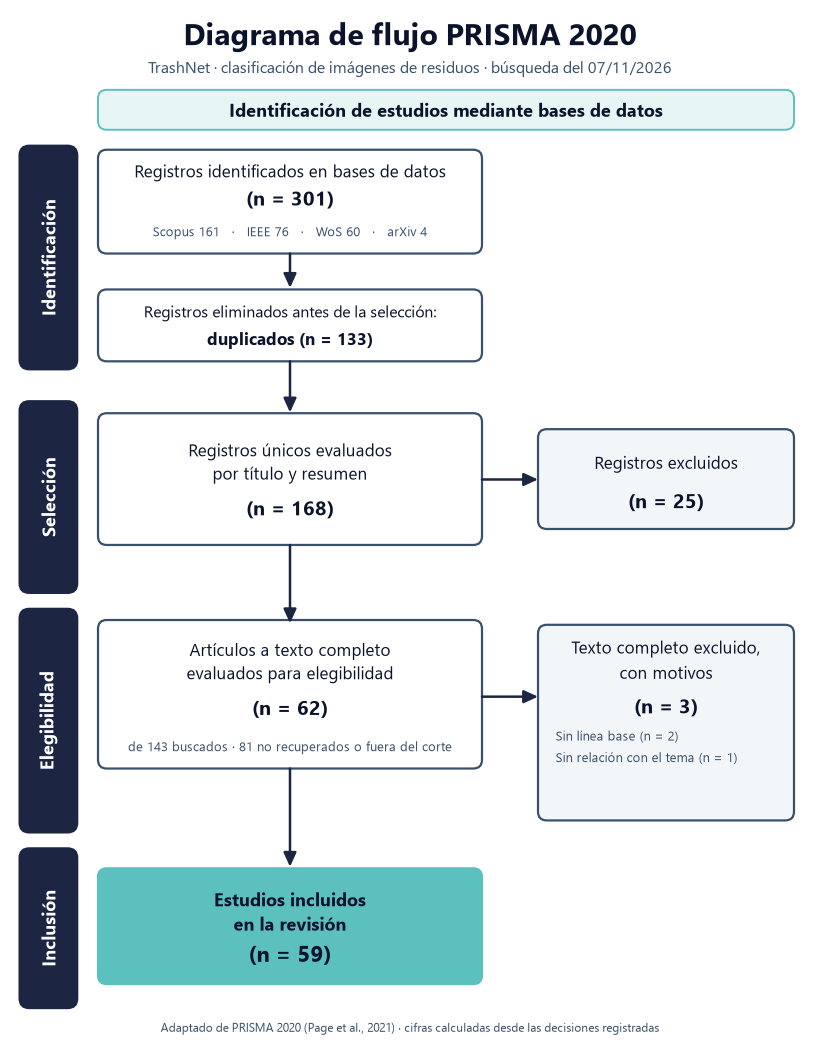

identificados=301 duplicados=133 únicos=168 excl.T/R=25 a TC=143 evaluados=62 no recuperados=81 excl.TC=3 incluidos=59


In [4]:
# ---- cifras derivadas de las decisiones registradas
total  = int(bit["n"].sum())
n_uni  = len(reg); n_dup = total - n_uni
n_exc_tr = int((reg["dec_tr"] == "Excluir").sum())
n_tc   = int(reg["dec_tr"].isin(["Incluir", "Dudoso"]).sum())
n_exc_tc = int((reg["dec_tc"] == "Excluir").sum())
n_inc  = int((reg["dec_tc"] == "Incluir").sum())
n_eval = n_exc_tc + n_inc; n_noret = n_tc - n_eval
motivos = reg.loc[reg["dec_tc"] == "Excluir", "motivo_tc"].value_counts()
CORTO = {"Sin relación directa con clasificación de imágenes de residuos": "Sin relación con el tema",
         "Sin modelo de referencia o línea base": "Sin línea base"}
por_base = dict(zip(bit["base"].str.replace("Web of Science", "WoS").str.replace(" Xplore", ""), bit["n"].astype(int)))

# ---- dibujo
K = 1.12                                       # factor de tamaño de letra
fig = plt.figure(figsize=(8, 10.3))
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 100); ax.set_ylim(0, 129); ax.axis("off")
def box(x, y, w, h, fc="white", ec=C2, lw=1.6, r=1.1):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}", fc=fc, ec=ec, lw=lw))
def txt(x, y, s, size=11, color=C0, weight="normal", ha="center", **kw):
    ax.text(x, y, s, fontsize=size * K, color=color, fontweight=weight, ha=ha, va="center", linespacing=1.45, **kw)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(
        arrowstyle="-|>,head_length=0.7,head_width=0.32", color=C1, lw=1.8, shrinkA=0, shrinkB=0))
def stage(y, h, label):
    box(1.2, y, 7.2, h, fc=C1, ec=C1, r=1.2); txt(4.8, y + h / 2, label, 11.5, "white", "bold", rotation=90)

XM, WM, XE, WE = 11, 48, 66, 32; cx = XM + WM / 2
txt(50, 125.6, "Diagrama de flujo PRISMA 2020", 19, C0, "bold")
txt(50, 121.6, "TrashNet · clasificación de imágenes de residuos · búsqueda del 07/11/2026", 10, C2)
box(11, 114, 87, 5, fc="#E8F5F5", ec=C3, lw=1.4)
txt(54.5, 116.5, "Identificación de estudios mediante bases de datos", 11.5, C0, "bold")
stage(84, 28, "Identificación")
box(XM, 98.5, WM, 13); txt(cx, 108.6, "Registros identificados en bases de datos")
txt(cx, 105.2, f"(n = {total})", 13, C0, "bold")
txt(cx, 101.1, "   ·   ".join(f"{b} {n}" for b, n in por_base.items()), 8.6, C2)
arrow(cx, 98.5, cx, 94.2)
box(XM, 85, WM, 9); txt(cx, 91.0, "Registros eliminados antes de la selección:", 10.2)
txt(cx, 87.6, f"duplicados (n = {n_dup})", 11, C0, "bold"); arrow(cx, 85, cx, 78.6)
stage(56, 24, "Selección")
box(XM, 62, WM, 16.5); txt(cx, 72.2, "Registros únicos evaluados\npor título y resumen")
txt(cx, 66.4, f"(n = {n_uni})", 13, C0, "bold")
box(XE, 64, WE, 12.5, fc="#F3F6F9"); txt(XE + WE / 2, 72.1, "Registros excluidos")
txt(XE + WE / 2, 67.3, f"(n = {n_exc_tr})", 13, C0, "bold")
arrow(XM + WM, 70.2, XE, 70.2); arrow(cx, 62, cx, 52.2)
stage(26, 28, "Elegibilidad")
box(XM, 34, WM, 18.6); txt(cx, 47.2, "Artículos a texto completo\nevaluados para elegibilidad")
txt(cx, 41.4, f"(n = {n_eval})", 13, C0, "bold")
txt(cx, 36.6, f"de {n_tc} buscados · {n_noret} no recuperados o fuera del corte", 8.4, C2)
box(XE, 27.5, WE, 24.5, fc="#F3F6F9"); txt(XE + WE / 2, 47.5, "Texto completo excluido,\ncon motivos")
txt(XE + WE / 2, 41.6, f"(n = {n_exc_tc})", 13, C0, "bold")
for k, (m, c) in enumerate(motivos.items()):
    txt(XE + 2.2, 38.0 - k * 2.7, f"{CORTO.get(m, m[:30])} (n = {c})", 8.2, C2, ha="left")
arrow(XM + WM, 43, XE, 43); arrow(cx, 34, cx, 21.7)
stage(4, 20, "Inclusión")
box(XM, 7, WM, 14.5, fc=C3, ec=C3)
txt(cx, 16.1, "Estudios incluidos\nen la revisión", 11.5, C0, "bold"); txt(cx, 10.6, f"(n = {n_inc})", 14, C0, "bold")
txt(50, 1.4, "Adaptado de PRISMA 2020 (Page et al., 2021) · cifras calculadas desde las decisiones registradas", 7.8, C2)
guardar(fig, "fig1_prisma.png"); plt.show()
print(f"identificados={total} duplicados={n_dup} únicos={n_uni} excl.T/R={n_exc_tr} "
      f"a TC={n_tc} evaluados={n_eval} no recuperados={n_noret} excl.TC={n_exc_tc} incluidos={n_inc}")

**Selección y resolución de desacuerdos.** La selección por título y resumen y la extracción del texto completo se apoyaron en IA (Claude), que registró la decisión, el motivo y los rasgos extraídos de cada documento. Repartimos los 168 registros entre los dos integrantes, con una muestra común de 25 para medir el acuerdo, y resolvimos por consenso las discrepancias entre la decisión de la IA y la humana.

> **Uso de IA.** La selección y la extracción contaron con apoyo de IA. De los 143 candidatos a texto completo, 81 no se evaluaron porque no se pudieron recuperar o quedaron por debajo del corte de prioridad; el diagrama lo refleja.

## 5. Panorama bibliométrico

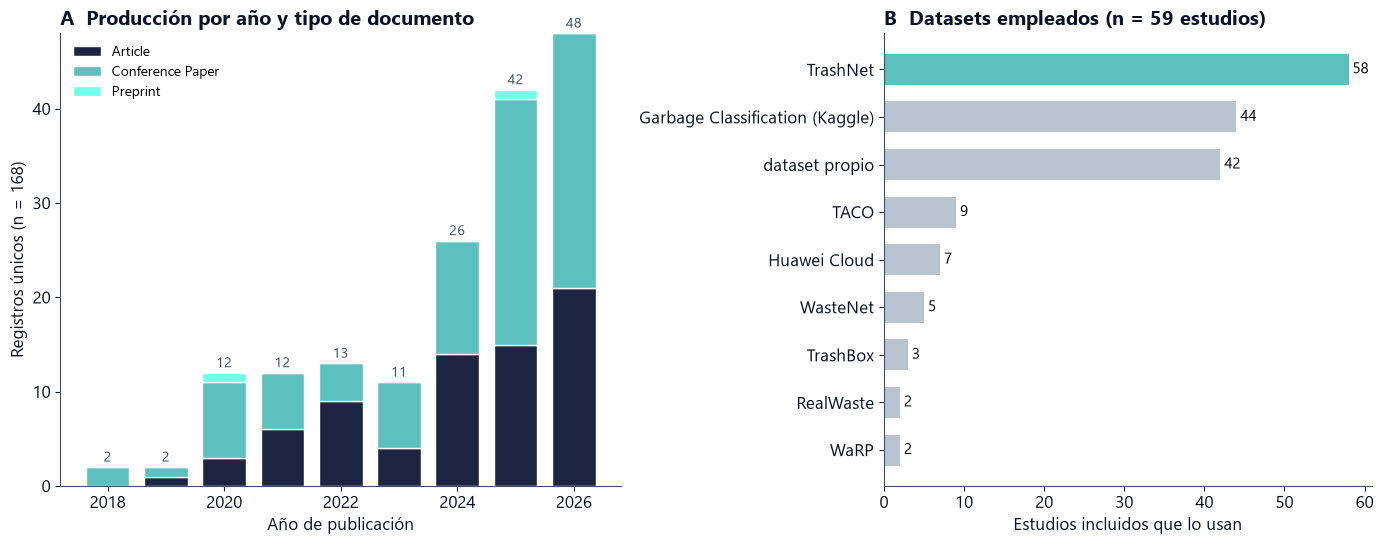

Estudios que combinan TrashNet con al menos otro dataset: 55 de 59


In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
# A. registros únicos por año y tipo
tipo = reg["tipo"].astype(str).str.capitalize().replace({"Conference paper": "Conference Paper"})
tipo = tipo.where(tipo.isin(["Article", "Conference Paper", "Preprint"]), "Otro")
t = pd.crosstab(reg["anio"].astype(int), tipo)
colores = {"Article": C1, "Conference Paper": C3, "Preprint": C4, "Otro": GRIS}
fondo = np.zeros(len(t))
for k in ["Article", "Conference Paper", "Preprint", "Otro"]:
    if k in t:
        a.bar(t.index, t[k], bottom=fondo, color=colores[k], label=k, width=0.75, edgecolor="white"); fondo += t[k].values
for x, y in zip(t.index, fondo): a.text(x, y + 0.6, int(y), ha="center", fontsize=10, color=C2)
a.set_xlabel("Año de publicación"); a.set_ylabel(f"Registros únicos (n = {len(reg)})")
a.set_title("A  Producción por año y tipo de documento", loc="left", fontweight="bold", color=C0)
a.legend(frameon=False, fontsize=10, loc="upper left")
# B. datasets usados por los 59 estudios incluidos
ds = est["datasets"].str.split(",").explode().str.strip().value_counts().sort_values()
b.barh(ds.index, ds.values, color=[C3 if i == "TrashNet" else GRIS for i in ds.index], height=0.65)
for y, v in enumerate(ds.values): b.text(v + 0.5, y, v, va="center", fontsize=11)
b.set_xlabel("Estudios incluidos que lo usan")
b.set_title(f"B  Datasets empleados (n = {len(est)} estudios)", loc="left", fontweight="bold", color=C0)
fig.tight_layout(); guardar(fig, "fig2_bibliometria.png"); plt.show()
print("Estudios que combinan TrashNet con al menos otro dataset:",
      int((est["datasets"].str.count(",") > 0).sum()), "de", len(est))

La producción crece desde 2024: el 69 % de los registros únicos corresponde a 2024–2026. La mayoría de los estudios valida en TrashNet y en un conjunto propio o de Kaggle, por lo que las cifras solo son comparables entre estudios con el mismo protocolo (partición, resolución y preentrenamiento).

## 6. Tabla de síntesis
La tabla resume, para cada estudio, la referencia, el problema, el conjunto de datos, los modelos de Deep Learning usados como referencia, las métricas reportadas y sus valores. Las familias de modelos se detectaron en el texto completo (al menos 5 menciones). Las métricas provienen del resumen de cada estudio (limitación 2, §14).

In [6]:
sintesis = est[["id", "ref", "datasets", "modelos", "metricas", "acc"]].rename(columns={
    "id": "ID", "ref": "Referencia", "datasets": "Dataset(s)",
    "modelos": "Modelos DL de referencia (familias)", "metricas": "Métricas y valores (resumen del autor)",
    "acc": "Exactitud TrashNet (%)"})
sintesis.insert(2, "Problema", "Clasificación de imágenes de residuos")
display(sintesis.style.hide(axis="index").format({"Exactitud TrashNet (%)": lambda v: "" if pd.isna(v) else f"{v:.2f}"})
        .set_properties(**{"text-align": "left", "font-size": "11px"}))
sintesis.to_csv(OUT / "tabla_sintesis.csv", index=False, encoding="utf-8-sig")   # para pegar en el informe

ID,Referencia,Problema,Dataset(s),Modelos DL de referencia (familias),Métricas y valores (resumen del autor),Exactitud TrashNet (%)
R001,"Mao W.-L., Chen W.-C., Wang C.-T. et al. (2021). Recycling waste classification using optimized convolutional neural network. Resources, Conservation and Recycling.",Clasificación de imágenes de residuos,"TrashNet, TACO, Garbage Classification (Kaggle), dataset propio","DenseNet, SVM (referencia clásica)","Métricas: exactitud, matriz de confusión, AUC/ROC. Valor del resumen del autor: The results show that the optimized DenseNet121 achieved the highest accuracy of 99.6%, when compared with other studies’ CNNs.",
R002,"Aral R.A., Keskin S.R., Kaya M. et al. (2018). Classification of TrashNet Dataset Based on Deep Learning Models. Proceedings - 2018 IEEE International Conference on Big Data, Big Data 2018.",Clasificación de imágenes de residuos,TrashNet,"Inception / InceptionResNet, DenseNet, MobileNet (V1/V2/V3), ResNet (cualquier profundidad), Xception","Métricas: exactitud, AUC/ROC. Valor del resumen del autor: As a result of the conducted experiments, the best results were found in the DenseNet121 using fine-tuning with a test accuracy rate of 95%.",
R003,"Vo A.H., Hoang Son L., Vo M.T. et al. (2019). A Novel Framework for Trash Classification Using Deep Transfer Learning. IEEE Access.",Clasificación de imágenes de residuos,"TrashNet, dataset propio","ResNeXt, ResNet (cualquier profundidad), DenseNet, Inception / InceptionResNet","Métricas: exactitud, precisión, matriz de confusión, AUC/ROC. Valor del resumen del autor: The experimental results indicate that DNN-TC yields 94% and 98% in terms of accuracy for Trashnet and VN-trash datasets respectively and thus it outperforms the state-of-the-art methods for trash classification on both experimental datasets.",
R004,"Rabano S.L., Cabatuan M.K., Sybingco E. et al. (2018). Common garbage classification using mobilenet. 2018 IEEE 10th International Conference on Humanoid, Nanotechnology, Information Technology, Communication and Control, Environment and Management, HNICEM 2018.",Clasificación de imágenes de residuos,"TrashNet, Garbage Classification (Kaggle)",MobileNet (V1/V2/V3),"Métricas: exactitud, recall, AUC/ROC, tiempo de inferencia. Valor del resumen del autor: The resulting baseline model, with a final test accuracy of 87.2% was optimized and quantized.",
R005,"Ruiz V., Sánchez Á., Vélez J.F. et al. (2019). Automatic Image-Based Waste Classification. Lecture Notes in Computer Science (including subseries Lecture Notes in Artificial Intelligence and Lecture Notes in Bioinformatics).",Clasificación de imágenes de residuos,"TrashNet, TACO, WaRP, dataset propio","SVM (referencia clásica), ResNet (cualquier profundidad), Inception / InceptionResNet, VGG, AlexNet / LeNet (CNN poco profunda)","Métricas: exactitud, precisión, recall, F1, matriz de confusión, AUC/ROC, kappa, promedio macro, tiempo de inferencia. Valor del resumen del autor: The best classification results were obtained using a combined Inception-ResNet model that achieved 88.6% of accuracy.",
R006,"Shi C., Tan C., Wang T. et al. (2021). A waste classification method based on a multilayer hybrid convolution neural network. Applied Sciences (Switzerland).",Clasificación de imágenes de residuos,"TrashNet, Garbage Classification (Kaggle)","VGG, ResNet (cualquier profundidad), AlexNet / LeNet (CNN poco profunda), MobileNet (V1/V2/V3), SVM (referencia clásica)","Métricas: exactitud, precisión, recall, F1, matriz de confusión, AUC/ROC, promedio macro. Valor del resumen del autor: A large number of experiments in a TrashNet dataset show that the proposed method achieves a classification accuracy of up to 92.6%, which is 4.18% and 4.6% higher than that of some state-of-the-art methods, and proves the effectiveness of the proposed method.",92.60
R008,"Hossen M.M., Majid M.E., Kashem S.B.A. et al. (2024). A Reliable and Robust Deep Learning Model for Effective Recyclable Waste Classificat

## 7. Calidad de los estudios
Evaluamos la claridad del protocolo, el control de la fuga de información, el número de repeticiones y el uso de pruebas estadísticas. Los indicadores se obtuvieron por lectura automática del texto completo (menciones explícitas) y constituyen una cota superior: mencionar una semilla no implica repetir el experimento con varias.

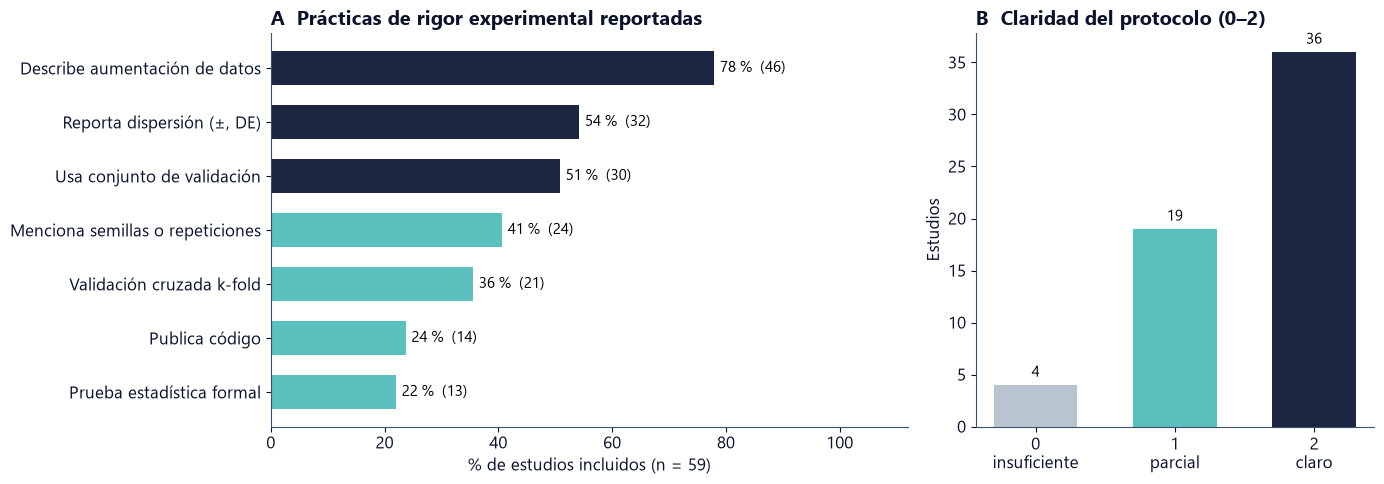

In [7]:
banderas = {"Describe aumentación de datos": "aumentacion", "Usa conjunto de validación": "validacion",
            "Reporta dispersión (±, DE)": "dispersion", "Menciona semillas o repeticiones": "semillas",
            "Validación cruzada k-fold": "kfold", "Publica código": "codigo", "Prueba estadística formal": "estadistica"}
pct = pd.Series({k: est[v].mean() * 100 for k, v in banderas.items()}).sort_values()
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})
a.barh(pct.index, pct.values, color=[C1 if v >= 50 else C3 for v in pct.values], height=0.62)
for y, v in enumerate(pct.values): a.text(v + 1, y, f"{v:.0f} %  ({round(v * len(est) / 100)})", va="center", fontsize=10.5)
a.set_xlim(0, 112); a.set_xlabel(f"% de estudios incluidos (n = {len(est)})")
a.set_title("A  Prácticas de rigor experimental reportadas", loc="left", fontweight="bold", color=C0)
p = est["protocolo"].value_counts().reindex([0, 1, 2], fill_value=0)
b.bar(["0\ninsuficiente", "1\nparcial", "2\nclaro"], p.values, color=[GRIS, C3, C1], width=0.6)
for x, v in enumerate(p.values): b.text(x, v + 0.8, v, ha="center", fontsize=11)
b.set_ylabel("Estudios"); b.set_title("B  Claridad del protocolo (0–2)", loc="left", fontweight="bold", color=C0)
fig.tight_layout(); guardar(fig, "fig3_calidad.png"); plt.show()

Solo 13 de los 59 estudios (22 %) aplican inferencia estadística y 27 no reportan dispersión. La mayoría compara modelos con una sola corrida y con diferencias de 1 a 3 puntos de accuracy, que pueden estar dentro de la variación entre semillas.

**Fuga de información.** No es posible evaluar automáticamente el control de fuga en cada estudio, pero el análisis exploratorio (capítulo 2) muestra que el riesgo existe en TrashNet: 3 fotografías aparecen con dos etiquetas distintas y hay 9 pares de casi-duplicados. Con una partición aleatoria, la más común en los estudios revisados, 3 de esos 9 pares quedan repartidos entre entrenamiento y prueba. Los estudios que no controlan los duplicados pueden sobreestimar su accuracy.

## 8. Frecuencia y complejidad de los modelos de referencia
La frecuencia cuenta, entre los 59 estudios incluidos, cuántos mencionan cada familia al menos 5 veces en el texto completo. Incluye el uso como *backbone* y no solo como línea base (limitación 3, §14). La complejidad corresponde a la versión de referencia de cada familia (pesos de ImageNet, 1000 clases).

Conteos corregidos para que coincidan con los 59 estudios incluidos (n previo -> n_59):
                             modelo  n  n_59
                                VGG 23    22
                           DenseNet 22    21
           SVM (referencia clásica) 17    14
AlexNet / LeNet (CNN poco profunda) 11     9
                            ResNeXt  8     7
                               YOLO  8     6


Familia,Tipo,Estudios,Variante de referencia,Parámetros (M),Sesgo inductivo,Decisión
ResNet (cualquier profundidad),Residual convolucional,39,ResNet-18,11.7,Bloques residuales: invariancia a traslación y gradiente estable en profundidad,PROPUESTO: ResNet de baja profundidad (18/34). Más frecuente (39 estudios); sesgo residual.
Inception / InceptionResNet,CNN multiescala,25,Inception-v3,27.2,Filtros de varios tamaños en paralelo,"No: más compleja y multiescala; frecuencia alta por ser backbone, no línea base simple."
MobileNet (V1/V2/V3),CNN ligera (separable en profundidad),24,MobileNetV2,3.5,Eficiencia: convolución separable,PROPUESTO: MobileNetV2 reducido. Muy frecuente (24); poco costoso; sesgo de convolución separable.
VGG,CNN profunda secuencial,22,VGG-16,138.4,Convoluciones 3x3 apiladas; muchos parámetros,PROPUESTO como VGG reducida / CNN secuencial pequeña con BatchNorm (23 estudios en VGG; LeNet/AlexNet 11). Sesgo: convolución secuencial simple.
DenseNet,CNN con conexiones densas,21,DenseNet-121,8.0,Reutilización de características,"Alternativa si se quisiera otro sesgo (reutilización de rasgos), pero más costosa."
SVM (referencia clásica),Clásico (no es DL),14,—,—,No cuenta: el enunciado pide Deep Learning,"no entra (más complejo, o no es DL de clasificación)"
EfficientNet,CNN con escalado compuesto,11,EfficientNet-B0,5.3,"Escala conjunta de profundidad, ancho y resolución","no entra (más complejo, o no es DL de clasificación)"
AlexNet / LeNet (CNN poco profunda),CNN poco profunda,9,AlexNet,61.1,Pocas capas; línea base simple,Respalda la CNN poco profunda: sirve de justificación para la VGG reducida.
Vision Transformer (ViT/Swin),Transformer de visión,8,ViT-B/16,86.6,Atención global; pocos sesgos locales,"no entra (más complejo, o no es DL de clasificación)"
ResNeXt,Residual con grupos,7,ResNeXt-50,25.0,Convolución agrupada,"no entra (más complejo, o no es DL de clasificación)"


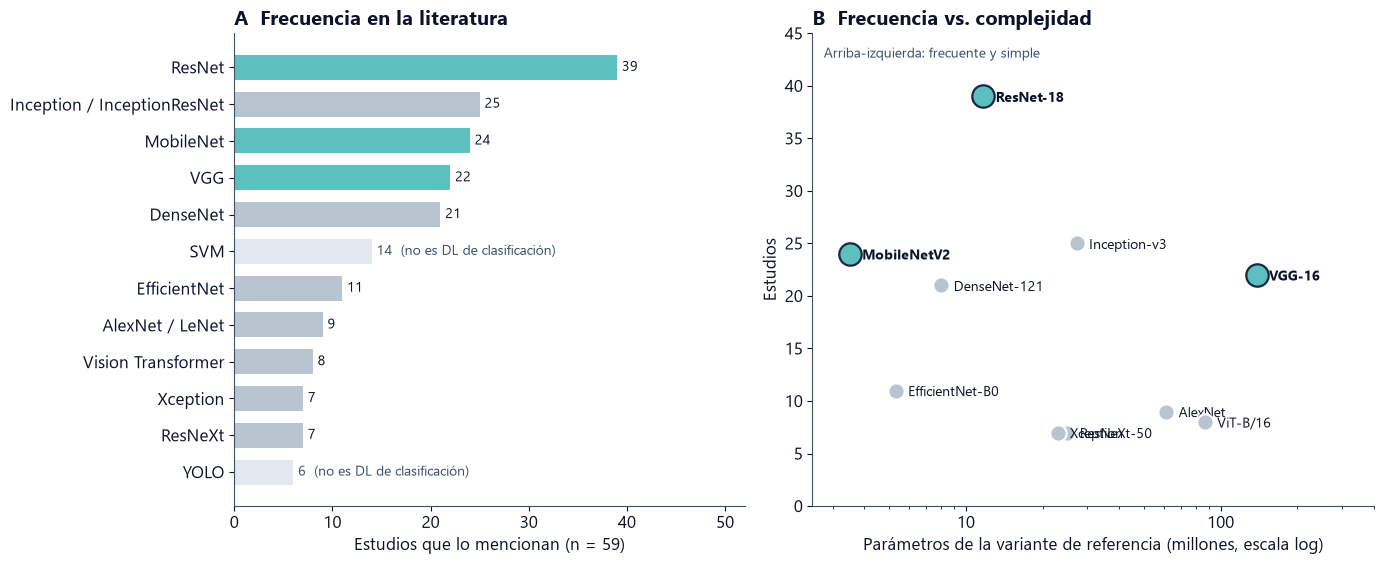

In [8]:
# Parámetros (millones) de la variante de referencia de cada familia (torchvision / keras.applications)
PARAMS = {"ResNet": ("ResNet-18", 11.7), "Inception": ("Inception-v3", 27.2), "MobileNet": ("MobileNetV2", 3.5),
          "VGG": ("VGG-16", 138.4), "DenseNet": ("DenseNet-121", 8.0), "AlexNet": ("AlexNet", 61.1),
          "EfficientNet": ("EfficientNet-B0", 5.3), "ResNeXt": ("ResNeXt-50", 25.0),
          "Vision Transformer": ("ViT-B/16", 86.6), "Xception": ("Xception", 22.9)}
def familia(m): return next((k for k in PARAMS if m.startswith(k)), None)
f = frec.copy()
cnt = est["modelos"].str.split(", ").explode().value_counts()       # conteo sobre los 59 incluidos
dif = f.assign(n_59=f["modelo"].map(cnt).fillna(0).astype(int)).query("n != n_59")[["modelo", "n", "n_59"]]
if len(dif):
    print("Conteos corregidos para que coincidan con los 59 estudios incluidos (n previo -> n_59):")
    print(dif.to_string(index=False))
f["n"] = f["modelo"].map(cnt).fillna(0).astype(int)
f = f.sort_values("n", ascending=False).reset_index(drop=True)
f["familia"] = f["modelo"].map(familia)
f["es_DL_clasif"] = f["familia"].notna()
f["variante"] = f["familia"].map(lambda k: PARAMS[k][0] if isinstance(k, str) else "—")
f["params_M"] = f["familia"].map(lambda k: PARAMS[k][1] if isinstance(k, str) else np.nan)
ELEGIDOS = {"ResNet", "MobileNet", "VGG"}
display(f[["modelo", "tipo", "n", "variante", "params_M", "sesgo", "decision"]].rename(columns={
    "modelo": "Familia", "tipo": "Tipo", "n": "Estudios", "variante": "Variante de referencia",
    "params_M": "Parámetros (M)", "sesgo": "Sesgo inductivo", "decision": "Decisión"}).style.hide(axis="index")
    .format({"Parámetros (M)": lambda v: "—" if pd.isna(v) else f"{v:.1f}"}).set_properties(**{"text-align": "left", "font-size": "11px"}))

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1, 1.1]})
g = f.sort_values("n")
a.barh(g["modelo"].str.replace(r"\s*\(.*\)", "", regex=True), g["n"],
       color=[C3 if k in ELEGIDOS else (GRIS if e else "#E3E8EE") for k, e in zip(g["familia"], g["es_DL_clasif"])], height=0.68)
for y, (v, e) in enumerate(zip(g["n"], g["es_DL_clasif"])):
    a.text(v + 0.5, y, f"{v}" + ("" if e else "  (no es DL de clasificación)"), va="center", fontsize=10, color=C0 if e else C2)
a.set_xlim(0, 52); a.set_xlabel(f"Estudios que lo mencionan (n = {len(est)})")
a.set_title("A  Frecuencia en la literatura", loc="left", fontweight="bold", color=C0)
h = f[f["es_DL_clasif"]]
for _, r in h.iterrows():
    sel = r["familia"] in ELEGIDOS
    b.scatter(r["params_M"], r["n"], s=260 if sel else 140, color=C3 if sel else GRIS, edgecolor=C1 if sel else "white", lw=1.6, zorder=3)
    b.annotate(r["variante"], (r["params_M"], r["n"]), xytext=(9, -4), textcoords="offset points", fontsize=10,
               color=C0, fontweight="bold" if sel else "normal")
b.set_xscale("log"); b.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}")); b.set_xlabel("Parámetros de la variante de referencia (millones, escala log)")
b.set_ylabel("Estudios"); b.set_xlim(2.5, 400); b.set_ylim(0, 45)
b.set_title("B  Frecuencia vs. complejidad", loc="left", fontweight="bold", color=C0)
b.text(0.02, 0.97, "Arriba-izquierda: frecuente y simple", transform=b.transAxes, fontsize=10, color=C2, va="top")
fig.tight_layout(); guardar(fig, "fig4_frecuencia_modelos.png"); plt.show()

## 9. Selección de los tres modelos base

| # | Modelo base | Familia en la literatura | Estudios | Sesgo inductivo |
|---|---|---|---|---|
| 1 | **CNN secuencial estilo VGG reducida** (bloques Conv3×3–BN–ReLU y MaxPool, *global average pooling*) | VGG + AlexNet/LeNet | 22 (+9) | Localidad y jerarquía de rasgos con convoluciones apiladas sin atajos |
| 2 | **MobileNetV2** (convolución separable en profundidad, normalización por lotes) | MobileNet | 24 | Separa el filtrado espacial de la combinación de canales |
| 3 | **ResNet-18** | ResNet | 39 | Aprende el residuo $F(x)=H(x)-x$ mediante atajos identidad |

**Criterio de selección.** Son las tres familias de clasificación más frecuentes con menor complejidad (cuadrante superior izquierdo de la Fig. 4B; de VGG usamos una versión reducida). Descartamos Inception (25 estudios) y DenseNet (21) porque aparecen sobre todo como *backbone* de modelos propuestos y no como líneas base, y porque son más complejas. SVM (14) no es Deep Learning y YOLO (6) es un modelo de detección.

**Diferencias entre los modelos.** La CNN apila convoluciones densas, MobileNetV2 usa convoluciones separables con cuellos de botella lineales y ResNet-18 usa bloques residuales. MobileNetV2 también contiene atajos (*inverted residuals*), por lo que su diferencia con ResNet-18 no es total; la diferencia principal está en la factorización de la convolución.

**Relación con la regresión logística.** Los tres modelos terminan en una capa lineal con *softmax*, que corresponde a una regresión logística multinomial:
$$p(y=k\mid x)=\frac{\exp(w_k^\top \phi_\theta(x)+b_k)}{\sum_{j=1}^{6}\exp(w_j^\top \phi_\theta(x)+b_j)},\qquad \mathcal L=-\frac1N\sum_i \log p(y_i\mid x_i).$$
En la regresión logística clásica los rasgos $\phi$ son fijos; en las CNN se aprenden, con sesgos de localidad y equivariancia a la traslación. Los modelos base cumplen la función de cota mínima, simple y reproducible, frente a la cual se mide un modelo más avanzado.

## 10. Desempeño reportado en TrashNet
Los valores de accuracy provienen del resumen de cada estudio y se contrastaron con la frase de origen. Como los estudios difieren en partición, resolución y preentrenamiento, y casi ninguno reporta intervalos, no los combinamos en un efecto agregado. La figura describe la distribución de los valores publicados.

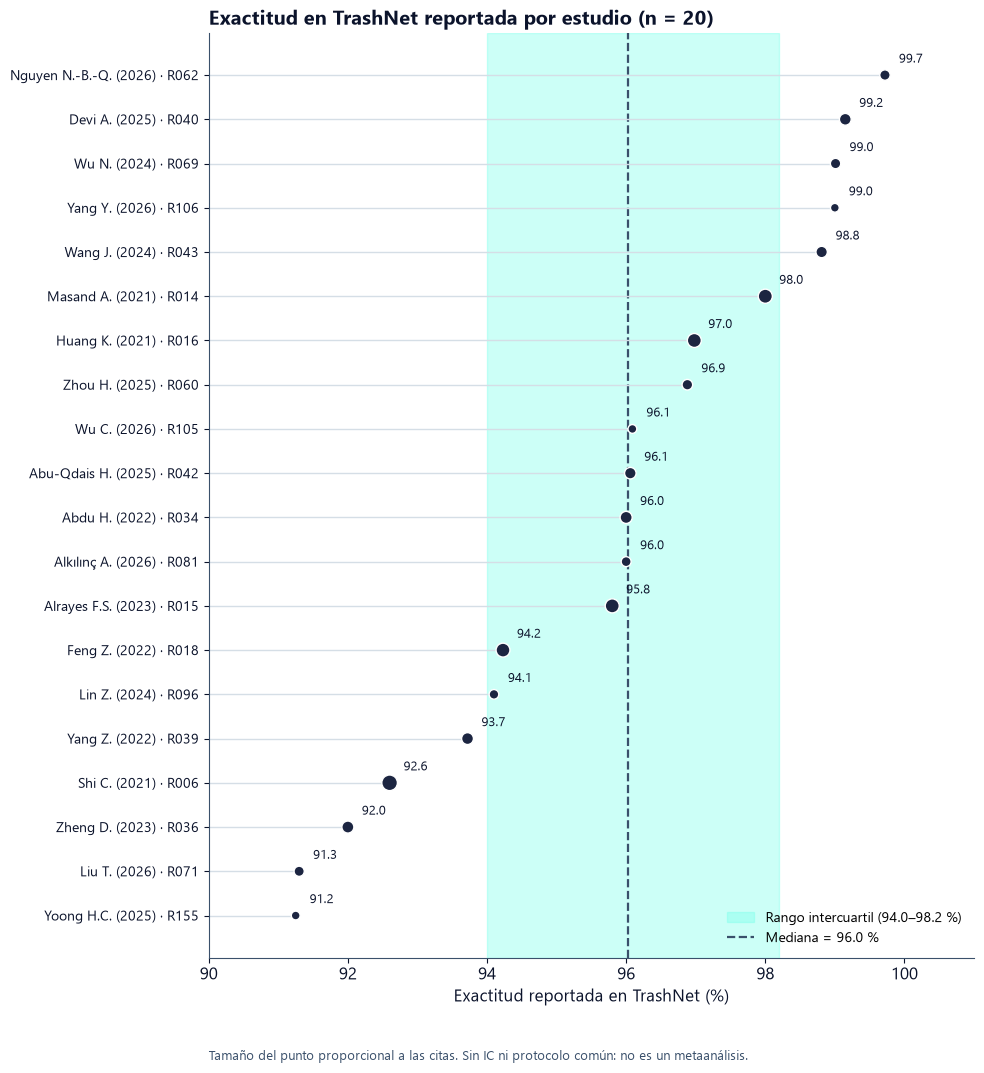

n=20  mediana=96.03  Q1=94.00  Q3=98.20  min=91.25  max=99.72


In [9]:
m = est.dropna(subset=["acc"]).copy()
m["autor"] = m["ref"].str.split(" \\(").str[0].str.split(",").str[0].str.strip()
m["et"] = m["autor"] + " (" + m["anio"].astype(str) + ") · " + m["id"]
m = m.sort_values("acc").reset_index(drop=True)
med, q1, q3 = m["acc"].median(), m["acc"].quantile(.25), m["acc"].quantile(.75)
fig, ax = plt.subplots(figsize=(10, 0.42 * len(m) + 2.4))
ax.axvspan(q1, q3, color=C4, alpha=.35, label=f"Rango intercuartil ({q1:.1f}–{q3:.1f} %)")
ax.axvline(med, color=C2, ls="--", lw=1.6, label=f"Mediana = {med:.1f} %")
lo = np.floor(m["acc"].min()) - 1
ax.hlines(m.index, lo, m["acc"], color="#D5DEE6", lw=1)
ax.scatter(m["acc"], m.index, s=40 + 8 * np.sqrt(m["citas"]), color=C1, edgecolor="white", zorder=3)
for y, v in zip(m.index, m["acc"]): ax.text(v + .2, y + .28, f"{v:.1f}", fontsize=9.5, color=C0)
ax.set_yticks(m.index); ax.set_yticklabels(m["et"], fontsize=10)
ax.set_xlim(lo, 101); ax.set_xlabel("Exactitud reportada en TrashNet (%)")
ax.set_title(f"Exactitud en TrashNet reportada por estudio (n = {len(m)})", loc="left", fontweight="bold", color=C0)
ax.legend(frameon=False, fontsize=10, loc="lower right")
ax.text(0, -0.1, "Tamaño del punto proporcional a las citas. Sin IC ni protocolo común: no es un metaanálisis.",
        transform=ax.transAxes, fontsize=9.5, color=C2, va="top")
fig.tight_layout(); guardar(fig, "fig5_exactitud_trashnet.png"); plt.show()
print(f"n={len(m)}  mediana={med:.2f}  Q1={q1:.2f}  Q3={q3:.2f}  min={m['acc'].min():.2f}  max={m['acc'].max():.2f}")

La mediana publicada (~96 %) corresponde en su mayoría a modelos propuestos con transferencia desde ImageNet y aumento de datos, a menudo evaluados con una sola corrida. La tomamos como referencia superior y no como meta de los modelos base, que entrenamos desde cero y evaluamos con F1 macro, varias semillas e intervalos de confianza sobre la partición agrupada del capítulo 2.


## 11. Análisis de los modelos base

Para cada modelo presentamos referencias, arquitectura, ecuaciones, sesgo inductivo, fortalezas, limitaciones y complejidad. Los tres se entrenan con el mismo protocolo (capítulo 4); solo cambia la arquitectura.

**Elementos comunes.** Los tres usan convolución 2D y terminan en una capa lineal con *softmax* (§9):

$$y_{c'}(i,j)=\sigma\Big(b_{c'}+\sum_{c=1}^{C_{in}}\sum_{u,v} W_{c',c}(u,v)\,x_c(i+u,\,j+v)\Big),$$

donde $x$ es el mapa de entrada con $C_{in}$ canales, $W$ el filtro $k\times k$ y $\sigma$ la activación ReLU. Una capa convolucional tiene $(k^2 C_{in}+1)\,C_{out}$ parámetros y requiere $H_{out}W_{out}\,k^2 C_{in} C_{out}$ multiplicaciones-acumulaciones (MAC) por imagen.

La normalización por lotes (BN) estandariza cada canal con la media $\mu_B$ y la varianza $\sigma_B^2$ del lote y lo reescala con dos parámetros aprendidos, $\hat z=\gamma\,(z-\mu_B)/\sqrt{\sigma_B^2+\epsilon}+\beta$. Añade $2C$ parámetros por capa y estabiliza el entrenamiento.

**Pérdida y optimización.** Entropía cruzada ponderada por clase, $\mathcal L=-\sum_i w_{y_i}\log p(y_i\mid x_i)/\sum_i w_{y_i}$, optimizada con AdamW, calentamiento lineal, decaimiento coseno de la tasa de aprendizaje y *early stopping* sobre validación.



### 11.1 CNN secuencial estilo VGG reducida

- **Referencias:** Simonyan y Zisserman (2015), *ICLR*, https://arxiv.org/abs/1409.1556. Antecedentes: LeCun et al. (1998), https://doi.org/10.1109/5.726791; Krizhevsky et al. (2017), https://doi.org/10.1145/3065386.
- **Arquitectura:** 4 bloques [Conv 3×3 → BN → ReLU → Conv 3×3 → BN → ReLU → MaxPool 2×2] con 32, 64, 128 y 256 canales, *global average pooling*, dropout y capa lineal de 256 a 6. No tiene atajos. Dos convoluciones 3×3 consecutivas cubren un campo receptivo de 5×5 con menos parámetros ($18C^2$ frente a $25C^2$) y una no linealidad adicional.
- **Sesgo inductivo:** localidad, equivariancia a la traslación y jerarquía de rasgos (bordes, texturas, partes, objeto).
- **Parámetros:** $P=\sum_{\ell}(9\,C_{\ell-1}+1)\,C_\ell + (C_L+1)\,K$, más $4C_\ell$ por capa de BN (2 aprendidos y 2 estadísticas).
- **Fortalezas:** es la arquitectura más simple de explicar y reproducir.
- **Limitaciones:** sin atajos, la profundidad útil es limitada por el desvanecimiento del gradiente. La cabeza densa del VGG original concentra más del 85 % de sus 138 M de parámetros; la reemplazamos por *global average pooling* para reducir el sobreajuste con unas 2500 imágenes.



### 11.2 MobileNetV2

- **Referencia:** Sandler, M., Howard, A., Zhu, M., Zhmoginov, A. y Chen, L.-C. (2018). *MobileNetV2: Inverted Residuals and Linear Bottlenecks*. CVPR, 4510–4520. https://doi.org/10.1109/CVPR.2018.00474
- **Arquitectura:** cada bloque (1) expande los canales con una convolución 1×1 por un factor $t=6$, (2) filtra cada canal por separado con una convolución 3×3 en profundidad (*depthwise*) y (3) proyecta a pocos canales con una convolución 1×1 lineal (cuello de botella lineal). Si la entrada y la salida tienen la misma forma, se suma la entrada.
- **Eficiencia:** una convolución estándar $k\times k$ cuesta $k^2 C_{in}C_{out}$ operaciones por píxel y la separable $k^2C_{in}+C_{in}C_{out}$. La razón es $1/C_{out}+1/k^2\approx 1/9$ para $k=3$.
- **Sesgo inductivo:** además de localidad y equivariancia, supone que las correlaciones espaciales y entre canales pueden modelarse por separado.
- **Parámetros por bloque (sin BN):** $t\,C_{in}^2 + 9\,tC_{in} + t\,C_{in}C_{out}$.
- **Fortalezas:** pocos parámetros y operaciones, adecuada para dispositivos con recursos limitados, como un sistema de clasificación en planta.
- **Limitaciones:** desde cero es más sensible a la tasa de aprendizaje y a la regularización; la convolución en profundidad es poco eficiente en algunas GPU.



### 11.3 ResNet-18

- **Referencia:** He, K., Zhang, X., Ren, S. y Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR, 770–778. https://doi.org/10.1109/CVPR.2016.90
- **Arquitectura:** convolución 7×7 con paso 2, MaxPool, 4 etapas de 2 bloques básicos con 64, 128, 256 y 512 canales, *global average pooling* y capa lineal. Cada bloque calcula
$$y=\mathrm{ReLU}\big(\mathcal F(x;W)+x\big),\qquad \mathcal F = \mathrm{BN}(W_2 * \mathrm{ReLU}(\mathrm{BN}(W_1 * x))),$$
y, cuando cambia la forma, el atajo es una convolución 1×1 con paso 2.
- **Funcionamiento:** el bloque aprende la corrección $\mathcal F(x)=H(x)-x$ respecto a la identidad. En la retropropagación, $\partial y/\partial x=\partial \mathcal F/\partial x+I$; el término $I$ conserva el gradiente aunque $\partial\mathcal F/\partial x$ sea pequeño.
- **Sesgo inductivo:** localidad, equivariancia, jerarquía y refinamiento sucesivo de la representación.
- **Parámetros por bloque básico:** $9C_{in}C+9C^2+4C$, más $C_{in}C+2C$ si el atajo usa proyección.
- **Fortalezas:** es la familia más usada en los estudios revisados (39 de 59) y la más estable al entrenar redes profundas.
- **Limitaciones:** unos 11 M de parámetros para unas 2500 imágenes; entrenada desde cero tiende a sobreajustar, y su capacidad facilita aprender los atajos de fondo identificados en el capítulo 2.


In [10]:

# ---- Parámetros y costo (MAC) analíticos, verificados contra los modelos de referencia (1000 clases, 224×224)
def conv(cin, cout, k, h, w, stride=1, bias=True, bn=False, groups=1):
    """Devuelve (parámetros, MAC, h_out, w_out) de una conv 2D con padding 'same'."""
    ho, wo = -(-h // stride), -(-w // stride)
    p = k * k * (cin // groups) * cout + (cout if bias else 0) + (2 * cout if bn else 0)
    return p, ho * wo * k * k * (cin // groups) * cout, ho, wo

def dense(d_in, d_out): return (d_in + 1) * d_out, d_in * d_out

def vgg_like(cfg, dense_units, n_cls, h=224, w=224, cin=3):
    """cfg: canales por conv; 'M' = MaxPool 2×2. Cabeza: GAP (si dense_units es lista) o flatten."""
    P = M = 0
    for c in cfg:
        if c == "M":
            h, w = h // 2, w // 2; continue
        p, m, h, w = conv(cin, c, 3, h, w); P += p; M += m; cin = c
    d_in = cin * h * w if dense_units is None else cin            # None = flatten (VGG original)
    for u in ([] if dense_units in (None, []) else dense_units) + [n_cls]:
        p, m = dense(d_in, u); P += p; M += m; d_in = u
    return P, M

def vgg16(n_cls=1000):
    cfg = [64, 64, "M", 128, 128, "M", 256, 256, 256, "M", 512, 512, 512, "M", 512, 512, 512, "M"]
    P, M = vgg_like(cfg, None, 4096)          # convs + primera densa sobre el aplanado (7·7·512 = 25088 -> 4096)
    p2, m2 = dense(4096, 4096); p3, m3 = dense(4096, n_cls)
    return P + p2 + p3, M + m2 + m3

def resnet18(n_cls=1000, h=224, w=224):
    p, M, h, w = conv(3, 64, 7, h, w, 2, bias=False, bn=True); P = p
    h, w = -(-h // 2), -(-w // 2)                                   # MaxPool 3×3 stride 2
    cin = 64
    for c, s in [(64, 1), (128, 2), (256, 2), (512, 2)]:
        for b in range(2):
            st = s if b == 0 else 1
            p1, m1, h2, w2 = conv(cin, c, 3, h, w, st, bias=False, bn=True)
            p2, m2, _, _ = conv(c, c, 3, h2, w2, 1, bias=False, bn=True)
            P += p1 + p2; M += m1 + m2
            if st != 1 or cin != c:
                p3, m3, _, _ = conv(cin, c, 1, h, w, st, bias=False, bn=True); P += p3; M += m3
            cin, h, w = c, h2, w2
    p, m = dense(512, n_cls)
    return P + p, M + m

def _div8(v, d=8):
    n = max(d, int(v + d / 2) // d * d)
    return n + d if n < 0.9 * v else n

def mobilenet_v2(n_cls=1000, alpha=1.0, h=224, w=224):
    cin = _div8(32 * alpha); last = _div8(1280 * max(1.0, alpha))
    P, M, h, w = conv(3, cin, 3, h, w, 2, bias=False, bn=True)
    for t, c, n, s in [(1, 16, 1, 1), (6, 24, 2, 2), (6, 32, 3, 2), (6, 64, 4, 2), (6, 96, 3, 1), (6, 160, 3, 2), (6, 320, 1, 1)]:
        cout = _div8(c * alpha)
        for i in range(n):
            st, hid = (s if i == 0 else 1), cin * t
            if t != 1:
                p, m, _, _ = conv(cin, hid, 1, h, w, 1, bias=False, bn=True); P += p; M += m
            p, m, h, w = conv(hid, hid, 3, h, w, st, bias=False, bn=True, groups=hid); P += p; M += m   # depthwise
            p, m, _, _ = conv(hid, cout, 1, h, w, 1, bias=False, bn=True); P += p; M += m              # proyección lineal
            cin = cout
    p, m, _, _ = conv(cin, last, 1, h, w, 1, bias=False, bn=True); P += p; M += m
    p, m = dense(last, n_cls)
    return P + p, M + m

# Verificación contra los totales publicados de torchvision (1000 clases)
ref = pd.DataFrame([
    ["VGG-16", vgg16()[0], 138_357_544], ["ResNet-18", resnet18()[0], 11_689_512],
    ["MobileNetV2 (α=1.0)", mobilenet_v2()[0], 3_504_872]], columns=["Modelo", "Parámetros (fórmula)", "Parámetros (torchvision)"])
ref["Coincide"] = ref["Parámetros (fórmula)"] == ref["Parámetros (torchvision)"]
display(ref.style.hide(axis="index").format({"Parámetros (fórmula)": "{:,}", "Parámetros (torchvision)": "{:,}"}))


Modelo,Parámetros (fórmula),Parámetros (torchvision),Coincide
VGG-16,"138,357,544","138,357,544",True
ResNet-18,"11,689,512","11,689,512",True
MobileNetV2 (α=1.0),"3,504,872","3,504,872",True


Modelo base,Parámetros (M),MAC por imagen (G)
"CNN estilo VGG reducida (4 bloques × 2 conv, GAP, densa 128)",1.21,2.587
MobileNetV2 (α = 1.0),2.23,0.300
MobileNetV2 reducida (α = 0.5),0.70,0.096
ResNet-18,11.18,1.814


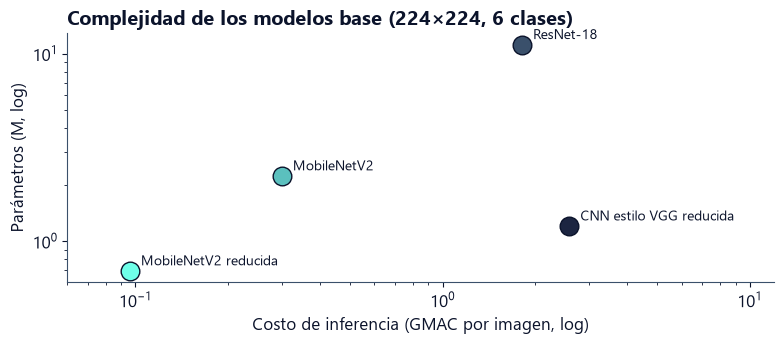

In [11]:

# ---- Complejidad de los modelos base para TrashNet (6 clases, entrada 224×224)
K = 6
VGG_RED = [32, 32, "M", 64, 64, "M", 128, 128, "M", 256, 256, "M"]   # configuración ILUSTRATIVA (se fija en la Sección 4)
filas = []
for nombre, (p, m) in [
        ("CNN estilo VGG reducida (4 bloques × 2 conv, GAP, densa 128)", vgg_like(VGG_RED, [128], K)),
        ("MobileNetV2 (α = 1.0)", mobilenet_v2(K, 1.0)),
        ("MobileNetV2 reducida (α = 0.5)", mobilenet_v2(K, 0.5)),
        ("ResNet-18", resnet18(K))]:
    filas.append([nombre, p / 1e6, m / 1e9])
comp = pd.DataFrame(filas, columns=["Modelo base", "Parámetros (M)", "MAC por imagen (G)"])
display(comp.style.hide(axis="index").format({"Parámetros (M)": "{:.2f}", "MAC por imagen (G)": "{:.3f}"}))
comp.to_csv(OUT / "complejidad_modelos_base.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 3.6))
for (_, r), col in zip(comp.iterrows(), [C1, C3, C4, C2]):
    ax.scatter(r["MAC por imagen (G)"], r["Parámetros (M)"], s=180, color=col, edgecolor=C0, zorder=3)
    ax.annotate(r["Modelo base"].split(" (")[0], (r["MAC por imagen (G)"], r["Parámetros (M)"]),
                xytext=(8, 4), textcoords="offset points", fontsize=10, color=C0)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.06, 12)
ax.set_xlabel("Costo de inferencia (GMAC por imagen, log)"); ax.set_ylabel("Parámetros (M, log)")
ax.set_title("Complejidad de los modelos base (224×224, 6 clases)", loc="left", fontweight="bold", color=C0)
fig.tight_layout(); guardar(fig, "fig6_complejidad_modelos_base.png"); plt.show()


**Costo de entrenamiento.** En los tres modelos, el costo de entrenamiento por imagen es del orden de tres veces el de inferencia (propagación hacia adelante y retropropagación) y crece linealmente con el número de píxeles. Los estudios revisados no reportan tiempos de entrenamiento comparables; los medimos en el capítulo 4 con el mismo hardware.

### 11.4 Uso de cada familia en los estudios incluidos

La tabla cuenta, entre los 59 estudios, cuántos usan cada familia, con qué conjuntos de datos y qué reportan. La accuracy extraída es la que cada estudio destaca en su resumen, casi siempre la de su modelo propuesto y no la de la línea base.

In [12]:

FAM = {"CNN estilo VGG (VGG)": "VGG", "CNN poco profunda (AlexNet/LeNet)": "AlexNet / LeNet (CNN poco profunda)",
       "MobileNet": "MobileNet (V1/V2/V3)", "ResNet": "ResNet (cualquier profundidad)"}
toks = est["modelos"].str.split(", ")
filas = []
for nombre, token in FAM.items():
    s = est[toks.apply(lambda L: token in L)]
    ds = s["datasets"].str.split(", ").explode().value_counts()
    a = s["acc"].dropna()
    filas.append([nombre, len(s), ", ".join(f"{k} ({v})" for k, v in ds.head(3).items()),
                  f"{a.median():.1f} [{a.min():.1f}–{a.max():.1f}] (n={len(a)})" if len(a) else "—",
                  f"{s['dispersion'].mean():.0%}", f"{s['estadistica'].mean():.0%}", f"{s['preentrenado'].mean():.0%}",
                  ", ".join(s.sort_values("citas", ascending=False)["id"].head(5))])
uso = pd.DataFrame(filas, columns=["Familia", "Estudios", "Datasets más usados", "Exactitud destacada en TrashNet, mediana [rango]",
                                   "Reporta dispersión", "Prueba estadística", "Usa preentrenamiento", "Estudios más citados (ID)"])
display(uso.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "11px"}))
uso.to_csv(OUT / "uso_por_familia.csv", index=False, encoding="utf-8-sig")


Familia,Estudios,Datasets más usados,"Exactitud destacada en TrashNet, mediana [rango]",Reporta dispersión,Prueba estadística,Usa preentrenamiento,Estudios más citados (ID)
CNN estilo VGG (VGG),22,"TrashNet (22), Garbage Classification (Kaggle) (20), dataset propio (16)",94.2 [91.2–96.9] (n=8),59%,18%,100%,"R005, R006, R010, R015, R018"
CNN poco profunda (AlexNet/LeNet),9,"TrashNet (9), Garbage Classification (Kaggle) (7), dataset propio (6)",92.6 [91.2–99.2] (n=3),44%,44%,100%,"R005, R006, R010, R026, R035"
MobileNet,24,"TrashNet (24), Garbage Classification (Kaggle) (19), dataset propio (17)",93.4 [91.2–99.2] (n=8),54%,29%,100%,"R002, R004, R006, R008, R011"
ResNet,39,"TrashNet (39), Garbage Classification (Kaggle) (29), dataset propio (27)",96.1 [91.2–99.7] (n=13),59%,26%,100%,"R002, R003, R005, R006, R008"



## 12. Comparación crítica

### 12.1 Desempeño, robustez y escalabilidad

| Criterio | CNN estilo VGG reducida | MobileNetV2 | ResNet-18 |
|---|---|---|---|
| **Uso y desempeño en la literatura (§11.4)** | 22 estudios; mediana de accuracy destacada 94.2 % (n = 8) | 24 estudios; mediana 93.4 % (n = 8) | 39 estudios; mediana 96.1 % (n = 13) |
| **Robustez esperada** | BN estabiliza el entrenamiento; sin atajos, la profundidad útil es limitada | BN la estabiliza, pero desde cero es sensible a la regularización | BN y atajos: la más estable al entrenar desde cero |
| **Escalabilidad (224×224)** | ≈ 1.2 M de parámetros y ≈ 2.6 GMAC, porque las primeras capas operan a resolución completa | ≈ 2.2 M de parámetros y ≈ 0.3 GMAC | ≈ 11.2 M de parámetros y ≈ 1.8 GMAC |
| **Riesgo con TrashNet** | Subajuste | Variabilidad entre semillas | Sobreajuste y aprendizaje del fondo |

Las medianas de la primera fila no permiten ordenar las familias: corresponden a la accuracy destacada por cada estudio, casi siempre de su modelo propuesto, y mezclan particiones, resoluciones, preentrenamiento y conjuntos de datos (44 de 59 estudios combinan TrashNet con el conjunto de Kaggle). La comparación controlada se presenta en el capítulo 5.

### 12.2 Validez de los estudios revisados

- **Partición:** heterogénea (50 % de prueba, 70/13/17, *k*-fold) y casi nunca agrupada por duplicados.
- **Fuga de información:** TrashNet contiene duplicados exactos con etiquetas contradictorias y casi-duplicados (capítulo 2); una partición aleatoria deja casi-duplicados entre entrenamiento y prueba.
- **Repeticiones:** la mayoría reporta una sola corrida; el 41 % menciona semillas o repeticiones (cota superior).
- **Pruebas estadísticas:** 22 % (13 de 59).
- **Comparabilidad:** la mayoría combina TrashNet con otros conjuntos de datos, lo que impide comparar cifras.
- **Validez externa:** todas las fotografías son de estudio con fondo blanco, y el fondo y la iluminación predicen la clase por encima del azar (capítulo 2). No identificamos estudios que controlen este atajo; la extracción automática no lo buscó de forma explícita.

### 12.3 Brecha entre modelos avanzados y modelos base

La mediana de accuracy en TrashNet (~96 %, §10) corresponde casi siempre a modelos propuestos y preentrenados en ImageNet; todos los estudios incluidos usan preentrenamiento. Las líneas base de esos estudios suelen quedar algunos puntos por debajo, pero la extracción automática no separa esos valores, por lo que no estimamos la brecha cuantitativa. Como nuestros modelos base se entrenan desde cero, esperamos una diferencia apreciable frente a ese valor, que refleja principalmente el efecto del preentrenamiento.


In [13]:

# ---- Brecha en la literatura, formulada de modo verificable con la tabla de estudios
tres = toks.apply(lambda L: all(t in L for t in ["VGG", "MobileNet (V1/V2/V3)", "ResNet (cualquier profundidad)"]))
brecha = pd.Series({
    "Mencionan las tres familias (VGG, MobileNet, ResNet)": int(tres.sum()),
    "  … y usan una prueba estadística formal": int((tres & est["estadistica"]).sum()),
    "  … y además mencionan semillas o repeticiones": int((tres & est["estadistica"] & est["semillas"]).sum()),
    "Estudios con prueba estadística formal (de 59)": int(est["estadistica"].sum()),
}, name="Estudios")
display(brecha.to_frame())


,Estudios
"Mencionan las tres familias (VGG, MobileNet, ResNet)",9
… y usan una prueba estadística formal,2
… y además mencionan semillas o repeticiones,0
Estudios con prueba estadística formal (de 59),13


### 12.4 Brecha identificada

> Ninguno de los 59 estudios incluidos compara las tres familias de modelos base (CNN estilo VGG, MobileNetV2 y ResNet) en TrashNet con varias corridas y una prueba estadística formal. De los 9 estudios que mencionan las tres familias, 2 usan alguna prueba estadística y ninguno menciona semillas o repeticiones. Tampoco identificamos estudios que usen una partición controlada por duplicados o que evalúen el atajo de fondo.

Nuestro trabajo aborda esta brecha: entrenamos los tres modelos base con el mismo protocolo, sobre la partición agrupada del capítulo 2, con F1 macro como métrica primaria, varias semillas, intervalos de confianza y pruebas pareadas. Los indicadores de semillas, pruebas y partición provienen de la extracción automática del texto completo (limitación 2, §14).

## 13. Relación con el análisis exploratorio y el diseño experimental

Cada brecha identificada en la literatura se examinó en el análisis exploratorio (capítulo 2). La tabla resume los resultados y las decisiones adoptadas en los capítulos 4 y 5.

| Hallazgo de la revisión | Resultado del análisis exploratorio | Decisión |
|---|---|---|
| TrashNet está desbalanceado y casi todos reportan solo accuracy | 2521 imágenes tras el análisis (`glass` 498, `metal` 409, `plastic` 480; las demás sin cambio); razón de desbalance 4.34 (`paper` 594 / `trash` 137); entropía normalizada 0.96 | Métrica primaria F1 macro (accuracy como secundaria); pérdida ponderada con pesos de entrenamiento |
| Pocos estudios controlan la fuga de información | 3 pares de fotografías idénticas con etiquetas distintas y 9 pares de casi-duplicados (6 reales, 3 falsos positivos) | Eliminar las 6 imágenes contradictorias y agrupar los casi-duplicados; partición estratificada y agrupada 1800/360/361 |
| Imágenes de estudio con un objeto sobre fondo blanco | Atajo confirmado: con solo el marco, balanced accuracy de 0.40 frente a 0.17 del azar; persiste sin `cardboard` (+0.16) | Aumento fotométrico en entrenamiento; evaluación con fondo sustituido y Grad-CAM |
| Desplazamiento entre particiones | χ² p = 1.0; ningún KS significativo; AUC adversarial 0.51–0.54; TOST equivalente en 14 de 16 comparaciones | Se mantiene la partición |
| Resoluciones distintas entre estudios | Todas las imágenes miden 512×384 (4:3) | Entrada de 224×224 para los tres modelos |
| La normalización varía entre estudios | Media por canal en entrenamiento: R 0.672, G 0.638, B 0.602 | Estadísticas de entrenamiento recalculadas a 224×224 |
| Unidad de independencia | 2521 imágenes en 2512 grupos | Unidad: el grupo de casi-duplicados; independencia entre fotografías de una misma sesión como supuesto |
| El 78 % no aplica inferencia estadística | — | Entre 6 y 10 semillas por modelo según un estudio piloto; Friedman, t pareada y Wilcoxon con Holm, McNemar, intervalos de confianza |
| Casi todos usan pesos preentrenados | — | Los tres modelos se entrenan desde cero con el mismo protocolo |


## 14. Limitaciones de la revisión
1. **Lectura parcial:** no se evaluaron 81 de los 143 candidatos a texto completo.
2. **Extracción automática:** las familias de modelos, los indicadores de calidad y las métricas provienen de texto extraído de los documentos y de los resúmenes; los tratamos como evidencia indicativa del conjunto y no como valores definitivos por estudio.
3. **Frecuencia y línea base:** el conteo incluye menciones como *backbone* o en trabajos relacionados.
4. **Apoyo de IA en la selección:** el acuerdo humano se midió en una muestra común de 25 registros.
5. **Término de búsqueda único:** favorece la comparabilidad, pero excluye estudios que usan solo otros conjuntos de datos de residuos.
6. **Conteos de frecuencia:** se recalcularon sobre los 59 estudios incluidos; algunas familias tenían conteos ligeramente mayores en la versión previa (por ejemplo, VGG pasó de 23 a 22), sin efecto sobre la selección.

## 15. Referencias

**Arquitecturas de los modelos base**

- He, K., Zhang, X., Ren, S. y Sun, J. (2016). Deep Residual Learning for Image Recognition. *CVPR*, 770–778. https://doi.org/10.1109/CVPR.2016.90
- Krizhevsky, A., Sutskever, I. y Hinton, G. E. (2017). ImageNet Classification with Deep Convolutional Neural Networks. *Communications of the ACM*, 60(6), 84–90. https://doi.org/10.1145/3065386
- LeCun, Y., Bottou, L., Bengio, Y. y Haffner, P. (1998). Gradient-Based Learning Applied to Document Recognition. *Proceedings of the IEEE*, 86(11), 2278–2324. https://doi.org/10.1109/5.726791
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A. y Chen, L.-C. (2018). MobileNetV2: Inverted Residuals and Linear Bottlenecks. *CVPR*, 4510–4520. https://doi.org/10.1109/CVPR.2018.00474
- Simonyan, K. y Zisserman, A. (2015). Very Deep Convolutional Networks for Large-Scale Image Recognition. *ICLR*. https://arxiv.org/abs/1409.1556
- Page, M. J. et al. (2021). The PRISMA 2020 statement. *BMJ*, 372, n71. https://doi.org/10.1136/bmj.n71

**Estudios incluidos (59)**

In [14]:
for _, r in est.sort_values(["anio", "id"]).iterrows():
    doi = f" https://doi.org/{r['doi']}" if r["doi"] else ""
    print(f"[{r['id']}] {r['ref']}{doi}")

[R002] Aral R.A., Keskin S.R., Kaya M. et al. (2018). Classification of TrashNet Dataset Based on Deep Learning Models. Proceedings - 2018 IEEE International Conference on Big Data, Big Data 2018. https://doi.org/10.1109/bigdata.2018.8622212
[R004] Rabano S.L., Cabatuan M.K., Sybingco E. et al. (2018). Common garbage classification using mobilenet. 2018 IEEE 10th International Conference on Humanoid, Nanotechnology, Information Technology, Communication and Control, Environment and Management, HNICEM 2018. https://doi.org/10.1109/hnicem.2018.8666300
[R003] Vo A.H., Hoang Son L., Vo M.T. et al. (2019). A Novel Framework for Trash Classification Using Deep Transfer Learning. IEEE Access. https://doi.org/10.1109/access.2019.2959033
[R005] Ruiz V., Sánchez Á., Vélez J.F. et al. (2019). Automatic Image-Based Waste Classification. Lecture Notes in Computer Science (including subseries Lecture Notes in Artificial Intelligence and Lecture Notes in Bioinformatics). https://doi.org/10.1007/978-3

---
### Conclusiones
- La revisión partió de 301 registros y concluyó con 59 estudios incluidos (PRISMA 2020), con TrashNet como término de búsqueda y el periodo 2018–2026.
- Seleccionamos como modelos base una CNN estilo VGG reducida, MobileNetV2 y ResNet-18, las familias de Deep Learning más frecuentes y de menor complejidad, con sesgos inductivos distintos.
- La literatura reporta una mediana de ~96 % de accuracy, pero solo el 22 % de los estudios aplica pruebas estadísticas y ninguno compara las tres familias con varias corridas y una prueba formal.
- El análisis exploratorio confirma dos riesgos poco controlados en la literatura: duplicados con etiquetas contradictorias y atajos de fondo e iluminación.